# **Exploratory Data Analysis - EDA**

## Mục lục
- [0. Giới thiệu tổng quan về Bộ dữ liệu](#0-gioi-thieu)
- [1. Tổng quan dataset](#1-tổng-quan-dataset)
- [2. Phân tích missing values](#2-phân-tích-missing-values)
- [3. Kiểm tra trùng lặp](#3-kiểm-tra-trùng-lặp)
- [4. Khám phá dữ liệu (EDA)](#4-khám-phá-dữ-liệu)
    - [4.1 Biến mục tiêu (Class Imbalance)](#41-phân-phối-biến-mục-tiêu-class-imbalance)
    - [4.2 Phân phối biến số](#42-phân-phối-biến-số-numerical-features)
    - [4.3 Phân phối biến phân loại](#43-phân-phối-biến-phân-loại)
    - [4.4 Tương quan với biến mục tiêu Depression](#44-tương-quan-với-biến-mục-tiêu-depression)
    - [4.5 Nhóm Student vs Working Professional](#55-phân-tích-theo-nhóm-student-vs-working-professional)
    - [4.6 Ma trận tương quan](#46-ma-trận-tương-quan)
    - [4.7 Phân tích Outliers](#47-phân-tích-outliers)
    - [4.8 So sánh phân phối Train vs Test](#48-so-sánh-phân-phối-train-vs-test)
- [5. Tổng kết EDA](#5-tổng-kết-EDA)


## 0. Giới thiệu tổng quan về Bộ dữ liệu <a id='0-gioi-thieu'></a>

### 1. Chủ đề của dữ liệu
* **Mô tả chủ đề và lĩnh vực:** Tập dữ liệu thuộc lĩnh vực **Sức khỏe tâm thần (Mental Health)** và **Khoa học dữ liệu y tế (Health Data Science)**. Chủ đề cốt lõi là **Phân loại nguy cơ trầm cảm (Depression Risk Classification)** — dự đoán khả năng mắc trầm cảm của một cá nhân dựa trên các yếu tố nhân khẩu học, lối sống, và áp lực học tập/công việc.
* **Ngữ cảnh thực tế (Real-world context):** Dữ liệu phản ánh thực trạng sức khỏe tâm thần trong cộng đồng người trưởng thành — bao gồm cả sinh viên lẫn người đi làm. Trong thực tế, bài toán này ứng dụng trực tiếp vào hệ thống **sàng lọc sức khỏe tâm thần tự động**, **tư vấn học đường và doanh nghiệp**, cũng như các nền tảng chăm sóc sức khỏe kỹ thuật số, giúp phát hiện sớm các cá nhân có nguy cơ cao cần được hỗ trợ tâm lý.

### 2. Nguồn gốc của dữ liệu
* **Nền tảng và URL:** Dữ liệu được lấy từ cuộc thi trên nền tảng Kaggle: [Playground Series S4E11 — Mental Health Dataset](https://www.kaggle.com/competitions/playground-series-s4e11)
* **Tác giả/Tổ chức gốc:** Bộ dữ liệu được tổng hợp bởi **Kaggle** (nhóm Playground Series), dựa trên tập dữ liệu gốc **Student Depression Dataset** được thu thập bởi cộng đồng nghiên cứu.
* **Ngày thu thập/Công bố:** Cuộc thi được công bố vào tháng **11 năm 2024** (Playground Series Season 4, Episode 11). Dữ liệu được tổng hợp và làm sạch bởi Kaggle từ nguồn khảo sát thực tế.

### 3. Bản quyền và Giấy phép
* **Giấy phép sử dụng:** Tập dữ liệu này được Kaggle phát hành dưới giấy phép **CC BY 4.0 (Creative Commons Attribution 4.0)**, cho phép sử dụng, chia sẻ và chỉnh sửa tự do với điều kiện ghi nhận nguồn gốc.
* **Tính hợp lệ cho mục đích giáo dục:** Hoàn toàn hợp lệ và được khuyến khích sử dụng cho mục đích học tập, giảng dạy, và thực hiện đồ án tại trường đại học.
* **Hạn chế và yêu cầu ghi công (Attribution):** Khi công bố kết quả nghiên cứu, cần trích dẫn nguồn cuộc thi Kaggle và tập dữ liệu gốc. Không sử dụng dữ liệu này để đưa ra chẩn đoán y tế mà không có sự kiểm chứng của chuyên gia.

### 4. Cách thức thu thập dữ liệu
* **Phương pháp thu thập:** Dữ liệu gốc được thu thập thông qua **khảo sát có cấu trúc (Structured Survey)** trực tuyến, nhắm vào hai nhóm đối tượng chính: sinh viên đại học và người đi làm tại Ấn Độ.
* **Quần thể mục tiêu và Phương pháp lấy mẫu:**
    * Mục tiêu: Thu thập thông tin đa chiều về lối sống, áp lực tinh thần, và tình trạng trầm cảm tự báo cáo.
    * Lấy mẫu: Đối tượng tham gia được mời thông qua kênh trực tuyến. Mỗi cá nhân tự điền bảng khảo sát gồm các câu hỏi về nhân khẩu học, thói quen sinh hoạt, áp lực học tập/công việc, và trả lời câu hỏi về tình trạng trầm cảm hiện tại. Kaggle sau đó tổng hợp và tạo thêm dữ liệu tổng hợp (synthetic augmentation) để tăng kích thước tập huấn luyện lên **140.700 mẫu (train)** và **93.800 mẫu (test)**.
* **Thời gian thu thập:** Dữ liệu khảo sát gốc được thu thập trước năm 2024, phản ánh bối cảnh xã hội và văn hóa Ấn Độ trong giai đoạn đó.
* **Hạn chế và Thiên lệch (Biases):**
    * *Thiên lệch tự báo cáo (Self-report Bias):* Nhãn `Depression` được xác định dựa trên câu trả lời chủ quan của người tham gia, không phải chẩn đoán lâm sàng chính thức. Do đó, có thể tồn tại nhiễu nhãn (label noise).
    * *Thiên lệch nhân khẩu học:* Quần thể khảo sát tập trung chủ yếu ở Ấn Độ, phản ánh góc nhìn văn hóa và giáo dục đặc thù của quốc gia này, hạn chế khả năng tổng quát hóa sang các nền văn hóa khác.
    * *Mất cân bằng lớp (Class Imbalance):* Tỉ lệ nhãn `Depression = 1` (~18.2%) thấp hơn đáng kể so với nhãn `Depression = 0` (~81.8%), tạo ra sự mất cân bằng cần được xử lý kỹ trong giai đoạn huấn luyện mô hình.
    * *Dữ liệu tổng hợp (Synthetic Data):* Phần lớn tập dữ liệu Kaggle được tạo ra bằng phương pháp tổng hợp thống kê, không hoàn toàn là dữ liệu khảo sát thực tế.

### 5. Lý do lựa chọn tập dữ liệu

Nhóm lựa chọn tập dữ liệu này vì các lý do sau:

* **Đáp ứng yêu cầu của đề bài:** Tập dữ liệu gồm hơn 140.000 mẫu và 2 nhãn phân loại (depression/no depression), vượt xa điều kiện tối thiểu, cung cấp đủ dữ liệu để huấn luyện mô hình học máy đáng tin cậy.

* **Tính thực tiễn cao:** Bài toán phát hiện trầm cảm là một vấn đề xã hội cấp thiết với ứng dụng thực tế rõ ràng trong y tế và tư vấn tâm lý, giúp nhóm có động lực nghiên cứu sâu hơn.

* **Cấu trúc dữ liệu đa dạng:** Dữ liệu bao gồm cả biến số liên tục (`Age`, `CGPA`, `Work/Study Hours`), biến thứ tự (`Sleep Duration`, `Dietary Habits`), biến nhị phân (`Gender`, `Suicidal Thoughts`), và biến phân loại có nhiều giá trị (`City`, `Profession`), tạo điều kiện thực hành đầy đủ các kỹ thuật tiền xử lý.

* **Thách thức thực tế (Real-world challenges):** Dữ liệu tồn tại nhiều vấn đề cần xử lý: missing values có cấu trúc (MNAR), giá trị nhiễu trong biến phân loại, mất cân bằng lớp, và sự khác biệt rõ rệt giữa hai nhóm sinh viên và người đi làm — đây là những thách thức điển hình trong Data Science thực tế.

* **Khả thi về mặt tính toán:** Dù quy mô lớn (>234.000 mẫu tổng cộng), pipeline tiền xử lý và các mô hình dự kiến vẫn có thể thực thi trên máy cá nhân trong thời gian hợp lý nhờ sử dụng các thư viện tối ưu (`pandas`, `scikit-learn`, `LightGBM`, `XGBoost`).

**Kết luận:** Bộ dữ liệu này là lựa chọn phù hợp để thực hành toàn diện quy trình **phân tích dữ liệu khám phá (EDA)** và **xây dựng mô hình phân loại nhị phân** theo yêu cầu của đồ án.

## Cài đặt & Khai báo **Thư viện** và **Gói phụ thuộc** <a id='1-khai-bao'></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11


## 1. Tổng quan dataset

In [2]:
train = pd.read_csv('data/raw/train.csv')
test  = pd.read_csv('data/raw/test.csv')

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print()
print("5 dòng đầu tiên của train set:")
train.head()


Train shape: (140700, 20)
Test shape : (93800, 19)

5 dòng đầu tiên của train set:


,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,Aaradhya,Female,49.0,Ludhiana,Working Professional,Chef,NaN,5.0,NaN,NaN,2.0,More than 8 hours,Healthy,BHM,No,1.0,2.0,No,0
1,1,Vivan,Male,26.0,Varanasi,Working Professional,Teacher,NaN,4.0,NaN,NaN,3.0,Less than 5 hours,Unhealthy,LLB,Yes,7.0,3.0,No,1
2,2,Yuvraj,Male,33.0,Visakhapatnam,Student,NaN,5.0,NaN,8.97,2.0,NaN,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
3,3,Yuvraj,Male,22.0,Mumbai,Working Professional,Teacher,NaN,5.0,NaN,NaN,1.0,Less than 5 hours,Moderate,BBA,Yes,10.0,1.0,Yes,1
4,4,Rhea,Female,30.0,Kanpur,Working Professional,Business Analyst,NaN,1.0,NaN,NaN,1.0,5-6 hours,Unhealthy,BBA,Yes,9.0,4.0,Yes,0


Dataset gồm hai tập: train (140.700 dòng × 20 cột) và test (93.800 dòng × 19 cột). Mỗi dòng đại diện cho một cá nhân được khảo sát về sức khỏe tâm thần.

Cột mục tiêu là `Depression` (chỉ có trong train), nhận giá trị nhị phân: 0 là không trầm cảm, 1 là có trầm cảm.

Quan sát ngay từ 5 dòng đầu có thể thấy cấu trúc missing rõ ràng: người đi làm (Working Professional) không có giá trị ở các cột `Academic Pressure`, `CGPA`, `Study Satisfaction`, trong khi sinh viên (Student) không có `Work Pressure`, `Job Satisfaction`. Đây là dấu hiệu của missing có cấu trúc, không phải lỗi ngẫu nhiên.


### 1.1 Kiểu dữ liệu các cột

In [3]:
print("Kiểu dữ liệu từng cột:")
print(train.dtypes)
print()

num_cols = train.select_dtypes(include='number').columns.tolist()
cat_cols = train.select_dtypes(include='object').columns.tolist()
num_cols = [c for c in num_cols if c not in ['id', 'Depression']]
cat_cols = [c for c in cat_cols if c != 'Name']

print(f"Biến số  (Numerical)   : {num_cols}")
print(f"Biến phân loại (Cat.)  : {cat_cols}")


Kiểu dữ liệu từng cột:
id                                         int64
Name                                      object
Gender                                    object
Age                                      float64
City                                      object
Working Professional or Student           object
Profession                                object
Academic Pressure                        float64
Work Pressure                            float64
CGPA                                     float64
Study Satisfaction                       float64
Job Satisfaction                         float64
Sleep Duration                            object
Dietary Habits                            object
Degree                                    object
Have you ever had suicidal thoughts ?     object
Work/Study Hours                         float64
Financial Stress                         float64
Family History of Mental Illness          object
Depression                                 int

Dataset có 8 biến số dạng `float64` và 9 biến phân loại dạng `object`.

Về kiểu dữ liệu, không có vấn đề nào cần chuyển đổi khẩn cấp. Tuy nhiên cần lưu ý hai điểm:

Thứ nhất, `Sleep Duration` mang bản chất thứ tự (ordinal) nhưng đang được lưu dạng chuỗi tự do, nên cần chuẩn hóa và chuyển thành số nguyên thứ tự ở bước preprocessing.

Thứ hai, `id` và `Name` không chứa thông tin dự đoán, cần loại bỏ trước khi đưa vào mô hình.


### 1.2 Thống kê mô tả

In [4]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,140700.0,70349.500000,40616.735775,0.00,35174.75,70349.50,105524.25,140699.0
Age,140700.0,40.388621,12.384099,18.00,29.00,42.00,51.00,60.0
Academic Pressure,27897.0,3.142273,1.380457,1.00,2.00,3.00,4.00,5.0
Work Pressure,112782.0,2.998998,1.405771,1.00,2.00,3.00,4.00,5.0
CGPA,27898.0,7.658636,1.464466,5.03,6.29,7.77,8.92,10.0
Study Satisfaction,27897.0,2.944940,1.360197,1.00,2.00,3.00,4.00,5.0
Job Satisfaction,112790.0,2.974404,1.416078,1.00,2.00,3.00,4.00,5.0
Work/Study Hours,140700.0,6.252679,3.853615,0.00,3.00,6.00,10.00,12.0
Financial Stress,140696.0,2.988983,1.413633,1.00,2.00,3.00,4.00,5.0
Depression,140700.0,0.181713,0.385609,0.00,0.00,0.00,0.00,1.0


Một số quan sát từ bảng thống kê:

**Age**: Tuổi dao động từ 18 đến 60, trung bình 40.4, median 42. Phân phối đối xứng (skew = -0.22), không có giá trị bất thường.

**Work/Study Hours**: Trung bình 6.25 giờ/ngày, min = 0, max = 12. Độ lệch chuẩn 3.85 cho thấy phân tán rộng, cần kiểm tra thêm ở biểu đồ histogram.

**Financial Stress, Work Pressure, Job Satisfaction, Study Satisfaction, Academic Pressure**: Tất cả đều dùng thang điểm 1–5, mean xấp xỉ 3.0, độ lệch chuẩn khoảng 1.4, phân phối khá đối xứng.

**CGPA**: Count chỉ 27.898 trong khi train có 140.700 dòng, tức chỉ ~19.8% dữ liệu có giá trị. Đây là xác nhận đây là biến chỉ dành cho sinh viên.

**Depression**: Mean = 0.182 xác nhận chỉ 18.2% mẫu có nhãn dương — bài toán mất cân bằng lớp cần xử lý.


# 2. Phân tích Missing Values

In [5]:
missing     = train.isnull().sum()
missing_pct = (missing / len(train) * 100).round(2)
missing_df  = pd.DataFrame({'Số lượng missing': missing, 'Tỉ lệ (%)': missing_pct})
missing_df  = missing_df[missing_df['Số lượng missing'] > 0].sort_values('Số lượng missing', ascending=False)

print("Các cột có missing values trong tập TRAIN:")
print(missing_df.to_string())


Các cột có missing values trong tập TRAIN:
                    Số lượng missing  Tỉ lệ (%)
Academic Pressure             112803      80.17
Study Satisfaction            112803      80.17
CGPA                          112802      80.17
Profession                     36630      26.03
Work Pressure                  27918      19.84
Job Satisfaction               27910      19.84
Dietary Habits                     4       0.00
Financial Stress                   4       0.00
Degree                             2       0.00


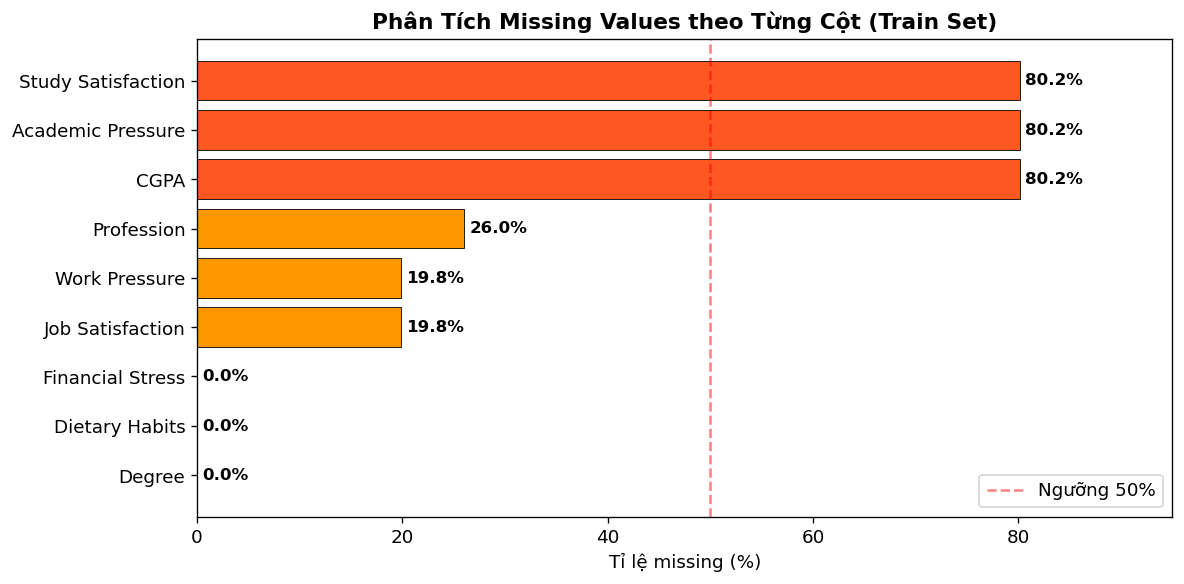

In [6]:
# Biểu đồ Missing Values – Train
missing_plot = (train.isnull().sum() / len(train) * 100)
missing_plot = missing_plot[missing_plot > 0].sort_values(ascending=True)

colors_bar = ['#FF5722' if x > 50 else '#FF9800' if x > 10 else '#FFC107' for x in missing_plot.values]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing_plot.index, missing_plot.values, color=colors_bar, edgecolor='black', linewidth=0.5)
for bar, val in zip(bars, missing_plot.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Tỉ lệ missing (%)')
ax.set_title('Phân Tích Missing Values theo Từng Cột (Train Set)', fontsize=13, fontweight='bold')
ax.set_xlim(0, 95)
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='Ngưỡng 50%')
ax.legend()
plt.tight_layout()
plt.show()


Dataset có ba nhóm missing với tính chất hoàn toàn khác nhau, cần xử lý riêng biệt.

**Nhóm 1 — Missing cấu trúc do sinh viên (~80.17%):** `Academic Pressure`, `Study Satisfaction`, `CGPA` đều thiếu đúng 112.802–112.803 dòng, tương đương 80.17%. Con số này trùng khớp chính xác với tỉ lệ người đi làm trong dataset (80.2%). Đây là dạng Missing Not At Random (MNAR): người đi làm không có điểm CGPA hay áp lực học tập, nên các ô này để trống là hợp lý về mặt logic. Không thể và không nên impute các giá trị này cho người đi làm.

**Nhóm 2 — Missing cấu trúc do người đi làm (~19.84%):** `Work Pressure` (27.918 dòng) và `Job Satisfaction` (27.910 dòng) thiếu gần đúng 19.84%, khớp với tỉ lệ sinh viên (19.8%). Tương tự nhóm 1, đây là MNAR theo chiều ngược lại.

**Nhóm 3 — Missing ngẫu nhiên:** `Profession` thiếu 36.630 dòng (26.03%). Con số này lớn hơn tỉ lệ sinh viên thuần túy, gợi ý một phần là do sinh viên không điền nghề nghiệp, một phần do nhiễu trong quá trình sinh dữ liệu tổng hợp. Cần xử lý thận trọng. `Dietary Habits` (4 dòng), `Financial Stress` (4 dòng), `Degree` (2 dòng) là sai sót thu thập rất nhỏ, không ảnh hưởng.

**Hướng xử lý ở bước Preprocessing:**
- Tách dataset thành hai sub-dataset: Student và Working Professional trước khi xử lý missing.
- Với nhóm Student: chỉ giữ và impute `Academic Pressure`, `CGPA`, `Study Satisfaction`; bỏ `Work Pressure`, `Job Satisfaction`.
- Với nhóm Working Professional: ngược lại.
- Hoặc tạo feature tổng hợp `Pressure` = `Academic Pressure` (Student) hoặc `Work Pressure` (Worker) để tránh mất thông tin.
- Ba cột missing gần 0 có thể drop dòng hoặc impute bằng mode.


# 3. Kiểm tra Trùng lặp

In [7]:
dup_rows = train.duplicated()
percent  = dup_rows.sum() / train.shape[0] * 100
print(f"Số dòng trùng lặp: {dup_rows.sum()} ({percent:.2f}%)")
print()
if dup_rows.sum() > 0:
    print("Các dòng trùng lặp:")
    display(train[train.duplicated(keep=False)])
else:
    print("Không có dòng trùng lặp trong tập train.")


Số dòng trùng lặp: 0 (0.00%)

Không có dòng trùng lặp trong tập train.


Tập train không có dòng nào trùng lặp hoàn toàn (0 dòng, 0.00%). Kết quả này phù hợp với bản chất của dataset — đây là dữ liệu tổng hợp (synthetic data) được sinh từ phân phối của dữ liệu khảo sát thực tế, nên mỗi bản ghi thường có giá trị duy nhất.

Không cần thực hiện bước drop duplicates trước khi training.


# 4. Khám phá dữ liệu (EDA)

## 4.1 Phân phối Biến Mục Tiêu (Class Imbalance)

Phân phối nhãn Depression:
  Không trầm cảm (0): 115,133 mẫu (81.8%)
  Trầm cảm       (1): 25,567 mẫu (18.2%)
  Tỉ lệ mất cân bằng: 4.5:1


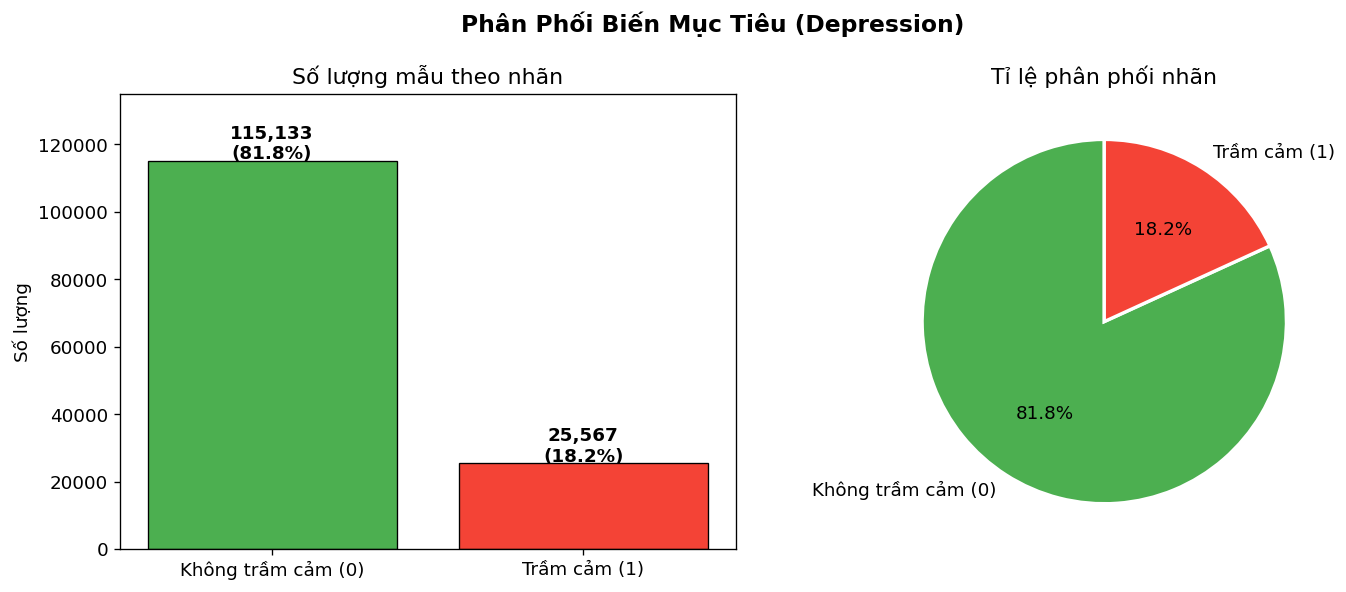

In [8]:
counts = train['Depression'].value_counts()
ratio  = round(counts[0] / counts[1], 2)

print("Phân phối nhãn Depression:")
print(f"  Không trầm cảm (0): {counts[0]:,} mẫu ({counts[0]/len(train)*100:.1f}%)")
print(f"  Trầm cảm       (1): {counts[1]:,} mẫu ({counts[1]/len(train)*100:.1f}%)")
print(f"  Tỉ lệ mất cân bằng: {ratio}:1")

labels = ['Không trầm cảm (0)', 'Trầm cảm (1)']
colors = ['#4CAF50', '#F44336']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Phân Phối Biến Mục Tiêu (Depression)', fontsize=14, fontweight='bold')

axes[0].bar(labels, counts.values, color=colors, edgecolor='black', linewidth=0.8)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 500, f'{v:,}\n({v/len(train)*100:.1f}%)', ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Số lượng mẫu theo nhãn')
axes[0].set_ylabel('Số lượng')
axes[0].set_ylim(0, 135000)

axes[1].pie(counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Tỉ lệ phân phối nhãn')

plt.tight_layout()
plt.show()


Dataset có 115.133 mẫu không trầm cảm (81.8%) và 25.567 mẫu trầm cảm (18.2%), tỉ lệ mất cân bằng 4.5:1.

Mức mất cân bằng này thuộc loại trung bình, không quá nghiêm trọng nhưng cũng đủ để gây ảnh hưởng nếu không xử lý. Nếu một mô hình đơn giản dự đoán toàn bộ là 0 (không trầm cảm), nó vẫn đạt Accuracy = 81.8% mà không học được bất kỳ pattern nào — đây là lý do Accuracy không nên là metric chính cho bài toán này.

**Hướng xử lý:**
- Dùng `class_weight='balanced'` trong các model sklearn (Logistic Regression, Random Forest, XGBoost) để tự động điều chỉnh trọng số.
- Hoặc áp dụng SMOTE để oversample lớp thiểu số (Depression = 1) trước khi training.
- Metric đánh giá nên là ROC-AUC (metric chính của cuộc thi), F1-score và Precision-Recall curve thay vì Accuracy.


## 4.2 Phân phối Biến Số (Numerical Features)

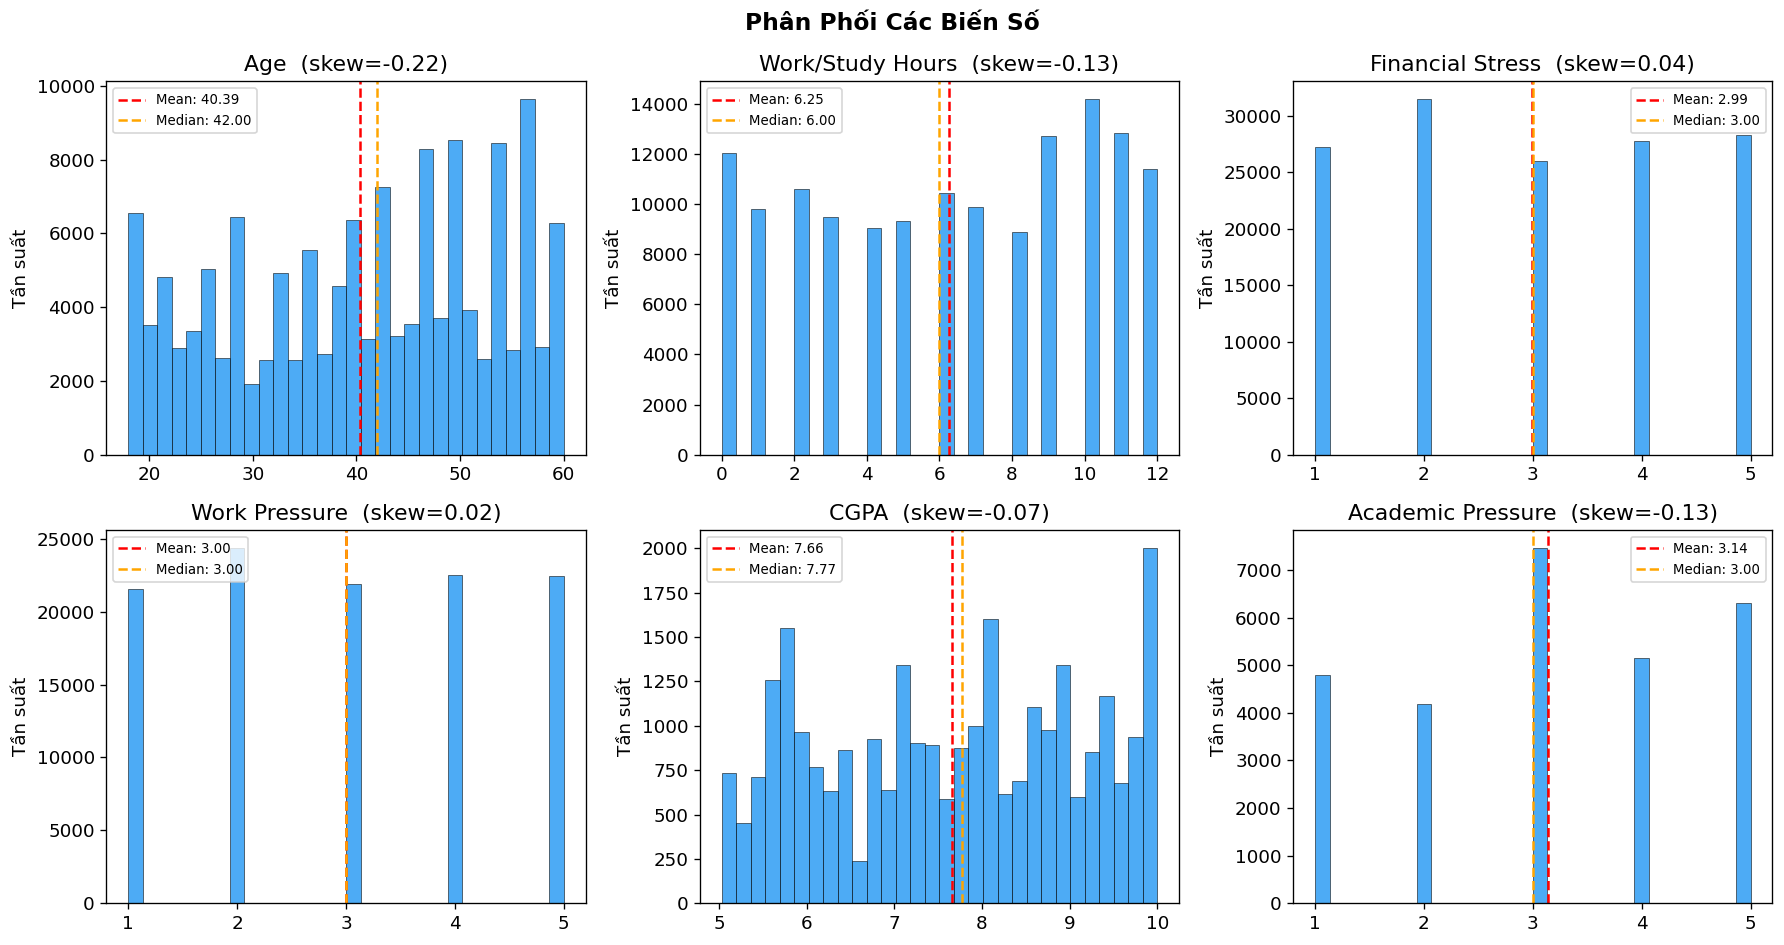


Thống kê phân phối:
                     mean  median     std   skew
Age                40.389   42.00  12.384 -0.218
Work/Study Hours    6.253    6.00   3.854 -0.128
Financial Stress    2.989    3.00   1.414  0.036
Work Pressure       2.999    3.00   1.406  0.019
CGPA                7.659    7.77   1.464 -0.074
Academic Pressure   3.142    3.00   1.380 -0.134


In [9]:
num_plot = ['Age', 'Work/Study Hours', 'Financial Stress', 'Work Pressure', 'CGPA', 'Academic Pressure']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Phân Phối Các Biến Số', fontsize=14, fontweight='bold')

for i, col in enumerate(num_plot):
    ax   = axes[i//3][i%3]
    data = train[col].dropna()
    ax.hist(data, bins=30, color='#2196F3', edgecolor='black', linewidth=0.4, alpha=0.8)
    ax.axvline(data.mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'Mean: {data.mean():.2f}')
    ax.axvline(data.median(), color='orange', linestyle='--', linewidth=1.5, label=f'Median: {data.median():.2f}')
    skew = data.skew()
    ax.set_title(f'{col}  (skew={skew:.2f})')
    ax.set_ylabel('Tần suất')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("\nThống kê phân phối:")
print(train[num_plot].agg(['mean','median','std','skew']).round(3).T)


**Kết quả thống kê phân phối:**

| Feature | Mean | Median | Std | Skew |
|---|---|---|---|---|
| Age | 40.389 | 42.00 | 12.384 | -0.218 |
| Work/Study Hours | 6.253 | 6.00 | 3.854 | -0.128 |
| Financial Stress | 2.989 | 3.00 | 1.414 | 0.036 |
| Work Pressure | 2.999 | 3.00 | 1.406 | 0.019 |
| CGPA | 7.659 | 7.77 | 1.464 | -0.074 |
| Academic Pressure | 3.142 | 3.00 | 1.380 | -0.134 |

Tất cả các biến đều có skewness rất nhỏ (gần 0), cho thấy phân phối gần đối xứng, không cần biến đổi log. Mean và Median gần nhau ở mọi biến, xác nhận không có lệch phân phối đáng kể. 

Biến `Age` có độ phân tán lớn nhất (std = 12.38). Đồng thời, `Work/Study Hours` cũng có độ phân tán khá rộng so với thang đo hẹp của nó (std = 3.85) — điều này phản ánh hành vi rất đa dạng trong tập dữ liệu, từ người không học/làm gì (0 giờ) đến người làm việc cực độ (12 giờ). Histogram của biến này cho thấy xu hướng đa đỉnh (multimodal) / bimodal nhẹ, gợi ý sự tồn tại của các nhóm đối tượng có hành vi phân hóa rõ rệt (ví dụ: Student và Working Professional).

**Hướng xử lý:** Với các model nhạy cảm với scale như Logistic Regression hay SVM, do các biến có thang đo rất khác nhau (tuổi lên tới 60, giờ làm tới 12, áp lực từ 1-5), cần chuẩn hóa bằng `StandardScaler`. Với tree-based models (XGBoost, LightGBM), không cần chuẩn hóa.

## 4.3 Phân phối Biến Phân Loại (Categorical Features)

In [ ]:
# Value counts cho tất cả biến phân loại
cat_all = ['Gender', 'Working Professional or Student', 'Sleep Duration',
           'Dietary Habits', 'Have you ever had suicidal thoughts ?',
           'Family History of Mental Illness', 'Degree']

for col in cat_all:
    vc = train[col].value_counts(dropna=False)
    print(f"\n{'='*50}")
    print(f"  {col}")
    print(f"{'='*50}")
    print(vc.to_string())




  Gender
Gender
Male      77464
Female    63236

  Working Professional or Student
Working Professional or Student
Working Professional    112799
Student                  27901

  Sleep Duration
Sleep Duration
Less than 5 hours    38784
7-8 hours            36969
More than 8 hours    32726
5-6 hours            32142
3-4 hours               12
6-7 hours                8
4-5 hours                7
4-6 hours                5
2-3 hours                5
6-8 hours                4
No                       4
1-6 hours                4
10-11 hours              2
9-11 hours               2
8-9 hours                2
Sleep_Duration           2
Unhealthy                2
45                       2
40-45 hours              1
1-2 hours                1
1-3 hours                1
9-6 hours                1
55-66 hours              1
Moderate                 1
35-36 hours              1
8 hours                  1
10-6 hours               1
Indore                   1
than 5 hours             1
49 hou

Nhận xét chi tiết từng biến phân loại:

**Gender:** Nam 77.464 (55.1%), Nữ 63.236 (44.9%). Tương đối cân bằng, không cần xử lý imbalance theo giới tính.

**Working Professional or Student:** 112.799 người đi làm (80.2%) và 27.901 sinh viên (19.8%). Đây là biến phân chia cấu trúc dataset và là nền tảng cho toàn bộ chiến lược xử lý missing.

**Sleep Duration:** Đây là biến có vấn đề dữ liệu nghiêm trọng nhất. Bốn giá trị chính hợp lệ là `Less than 5 hours` (38.784), `7-8 hours` (36.969), `More than 8 hours` (32.726), `5-6 hours` (32.142) — tổng ~140.621 dòng. Ngoài ra còn ~79 dòng chứa các giá trị rác như `Sleep_Duration`, `Unhealthy`, `45`, `Indore`, `Moderate`, `Work_Study_Hours`, `55-66 hours`, `9-5`, v.v. Rõ ràng có hiện tượng dữ liệu bị nhập sai cột hoặc nhiễu từ quá trình sinh synthetic data. Cần làm sạch trước khi encode.

**Dietary Habits:** Ba giá trị chính là `Moderate` (49.705), `Unhealthy` (46.227), `Healthy` (44.741). Ngoài ra có khoảng 20 dòng chứa giá trị rác tương tự Sleep Duration (`Male`, `BSc`, `Mihir`, `Gender`, `1.0`, v.v.). Cần drop hoặc gán NaN cho các giá trị không thuộc tập hợp {Moderate, Unhealthy, Healthy}.

**Have you ever had suicidal thoughts?:** `No` 71.138 (50.5%), `Yes` 69.562 (49.5%). Phân phối gần như cân bằng hoàn toàn. Đây là biến nhị phân sạch, không cần xử lý.

**Family History of Mental Illness:** `No` 70.758 (50.3%), `Yes` 69.942 (49.7%). Tương tự, phân phối cân bằng tốt.

**Degree:** Có hơn 28 loại bằng cấp hợp lệ, trong đó `Class 12` (14.729), `B.Ed` (11.691), `B.Arch` (8.742) là phổ biến nhất. Ngoài ra còn hàng chục giá trị rác chỉ có 1–2 lần xuất hiện như tên người (`Jhanvi`, `Aarav`, `Vivaan`), số CGPA (`5.61`, `8.56`), nghề nghiệp (`Data Scientist`, `Plumber`). Cần làm sạch, sau đó có thể nhóm lại theo cấp độ học vấn (undergraduate/postgraduate/doctorate) để giảm cardinality.

**Hướng xử lý Noisy Categorical Data:**
- `Sleep Duration`: Chỉ giữ 4 giá trị hợp lệ, map sang ordinal (1=<5h, 2=5-6h, 3=7-8h, 4=>8h). Drop hoặc gán NaN cho phần còn lại.
- `Dietary Habits`: Chỉ giữ {Healthy, Moderate, Unhealthy}, gán NaN cho các giá trị khác, sau đó impute bằng mode.
- `Degree`: Làm sạch các giá trị rác, sau đó nhóm lại theo cấp độ hoặc dùng target encoding do high cardinality.


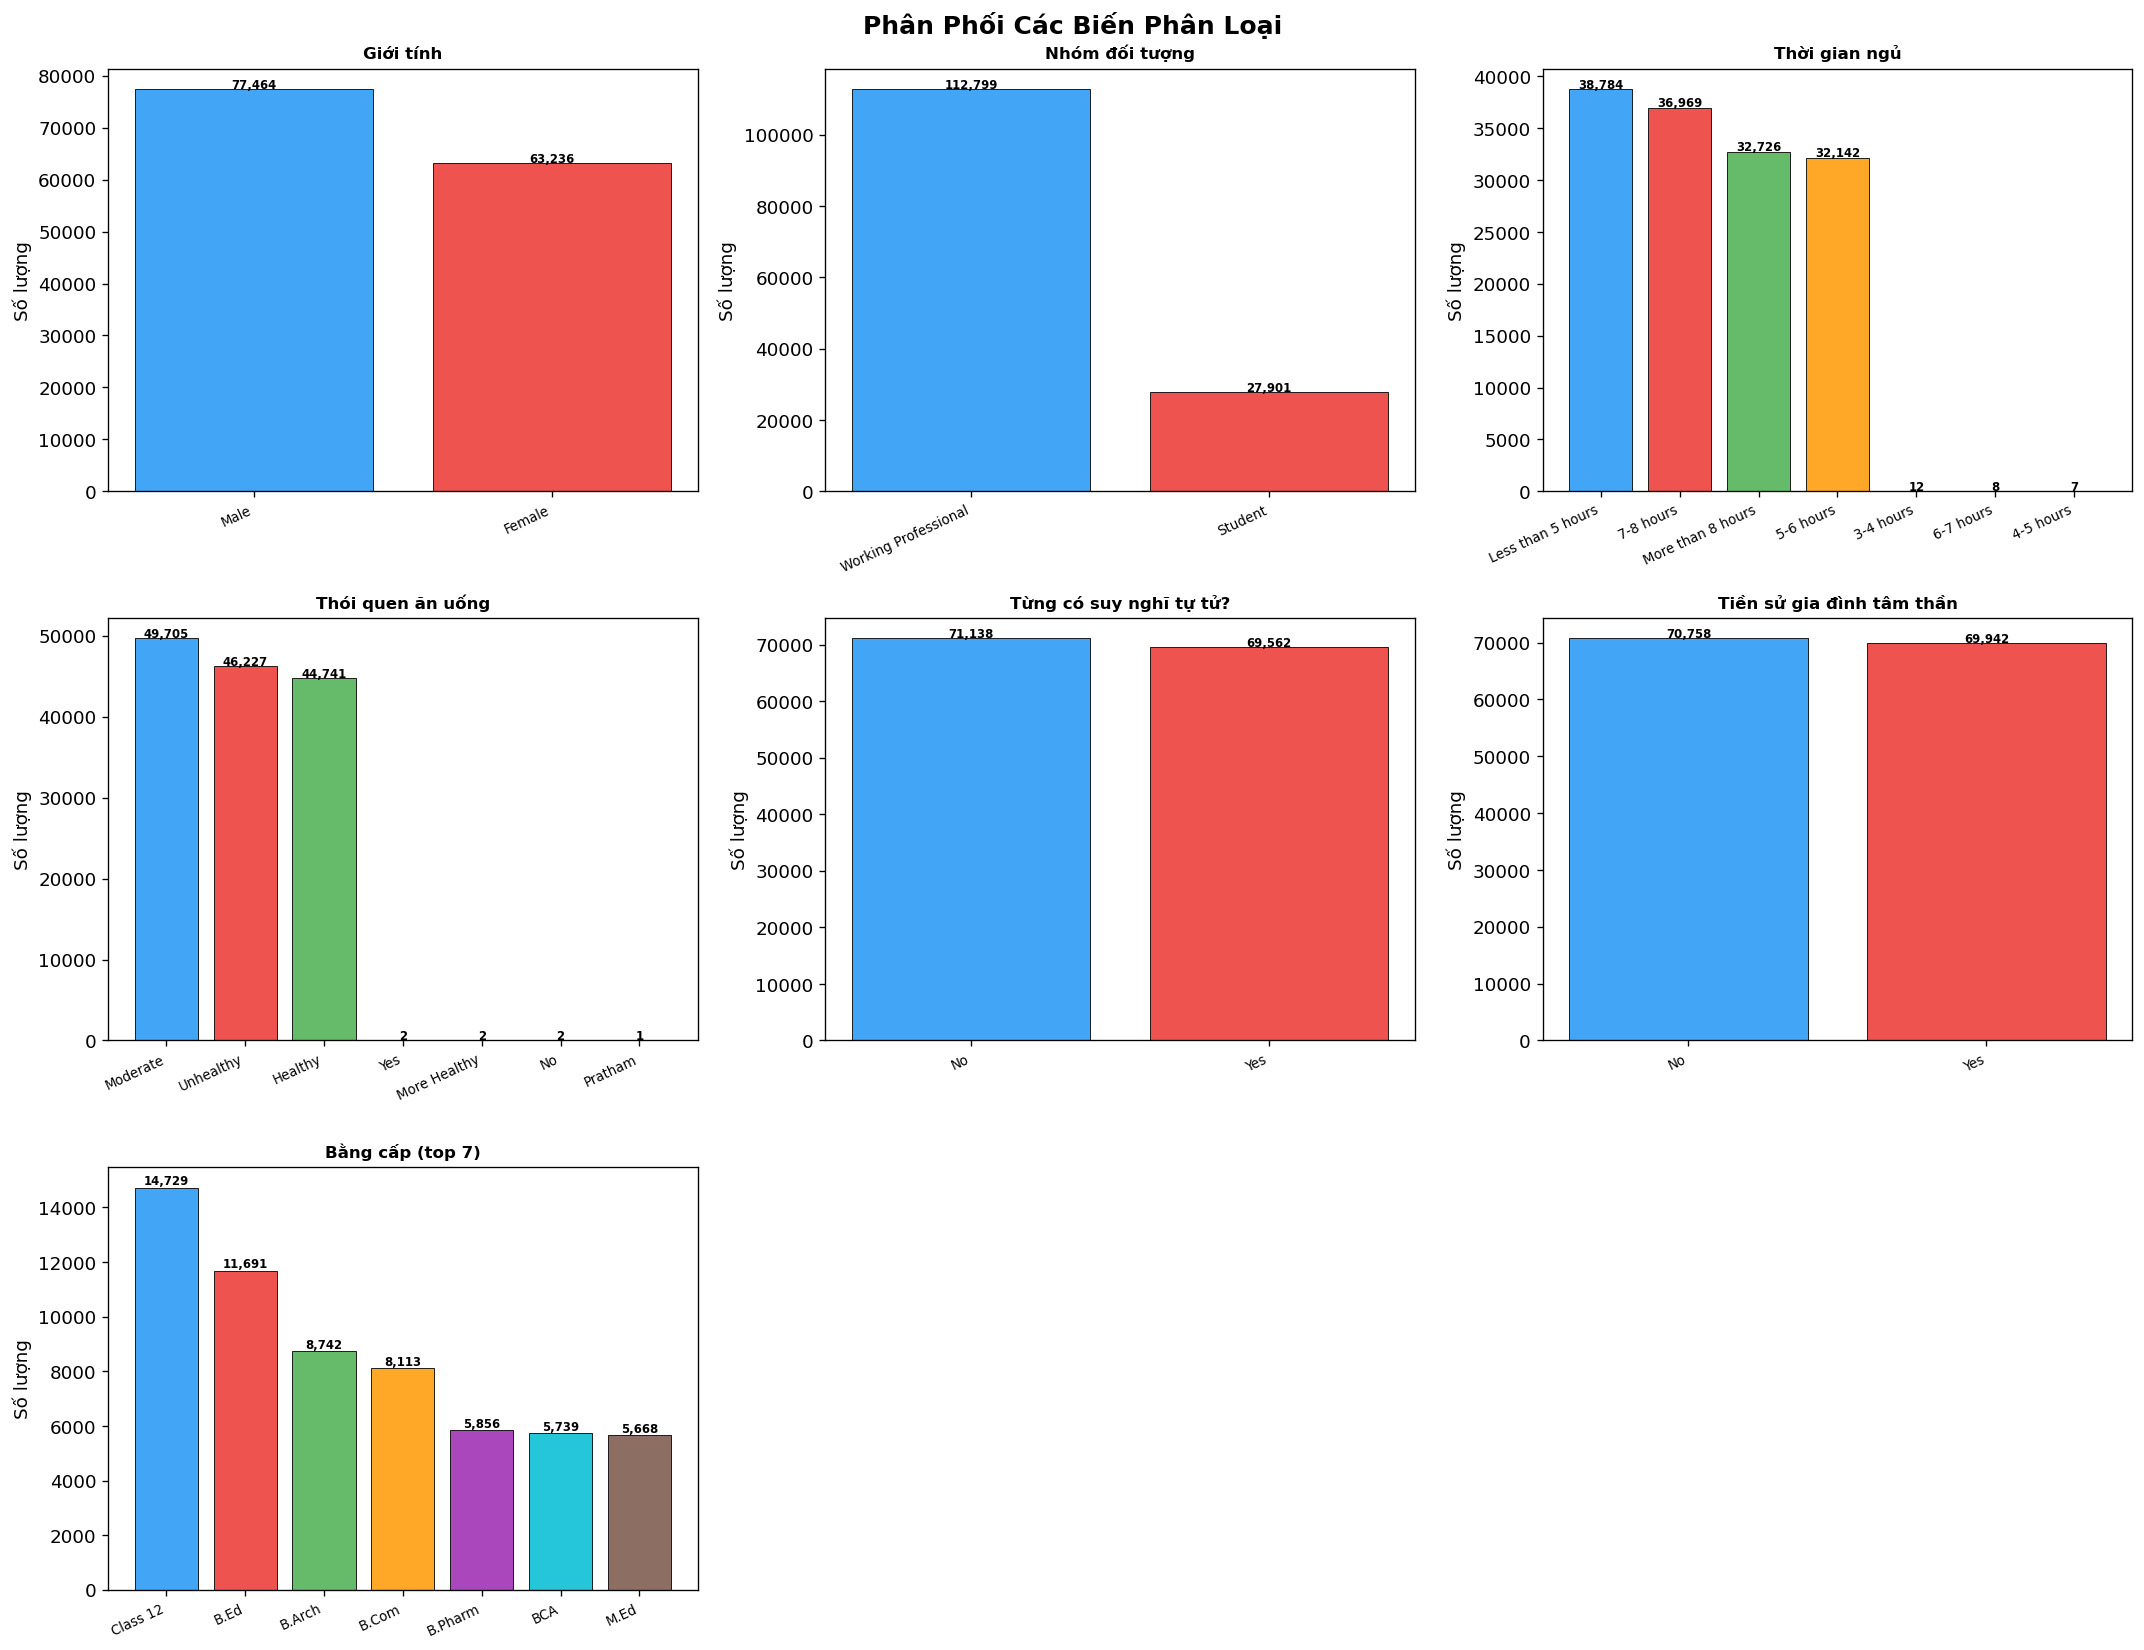

In [ ]:
# Biểu đồ tất cả biến phân loại
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle('Phân Phối Các Biến Phân Loại', fontsize=15, fontweight='bold')
axes = axes.flatten()
colors_cat = ['#42A5F5', '#EF5350', '#66BB6A', '#FFA726', '#AB47BC', '#26C6DA', '#8D6E63']

cat_plot_all = [
    ('Gender',                                'Giới tính'),
    ('Working Professional or Student',        'Nhóm đối tượng'),
    ('Sleep Duration',                         'Thời gian ngủ'),
    ('Dietary Habits',                         'Thói quen ăn uống'),
    ('Have you ever had suicidal thoughts ?',  'Từng có suy nghĩ tự tử?'),
    ('Family History of Mental Illness',       'Tiền sử gia đình tâm thần'),
    ('Degree',                                 'Bằng cấp (top 7)'),
]

for idx, (col, title) in enumerate(cat_plot_all):
    ax = axes[idx]
    vc = train[col].value_counts().head(7)
    bars = ax.bar(range(len(vc)), vc.values, color=colors_cat[:len(vc)], edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels(vc.index, rotation=25, ha='right', fontsize=8)
    for j, v in enumerate(vc.values):
        ax.text(j, v + 100, f'{v:,}', ha='center', fontsize=7, fontweight='bold')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel('Số lượng')

for idx in range(len(cat_plot_all), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()


Biểu đồ xác nhận trực quan các nhận xét từ value_counts ở trên. Đáng chú ý:

`Sleep Duration` trông tương đối đều giữa 4 nhóm chính khi vẽ top values, nhưng ẩn dưới đó là ~79 giá trị nhiễu. Biểu đồ không thể hiện được vấn đề này — đây là lý do cần kết hợp cả value_counts và biểu đồ khi phân tích categorical.

`Degree` có tính phân mảnh cao — top 7 chỉ chiếm khoảng 45% tổng số, còn lại trải đều trên hơn 20 loại. Với model tree-based, có thể dùng target encoding hoặc frequency encoding thay vì one-hot để tránh chiều dữ liệu quá lớn.


## 4.4 Tương quan từng Feature với Biến Mục Tiêu Depression

### 4.4.1 Biến phân loại × Depression (Tỉ lệ trầm cảm theo nhóm)

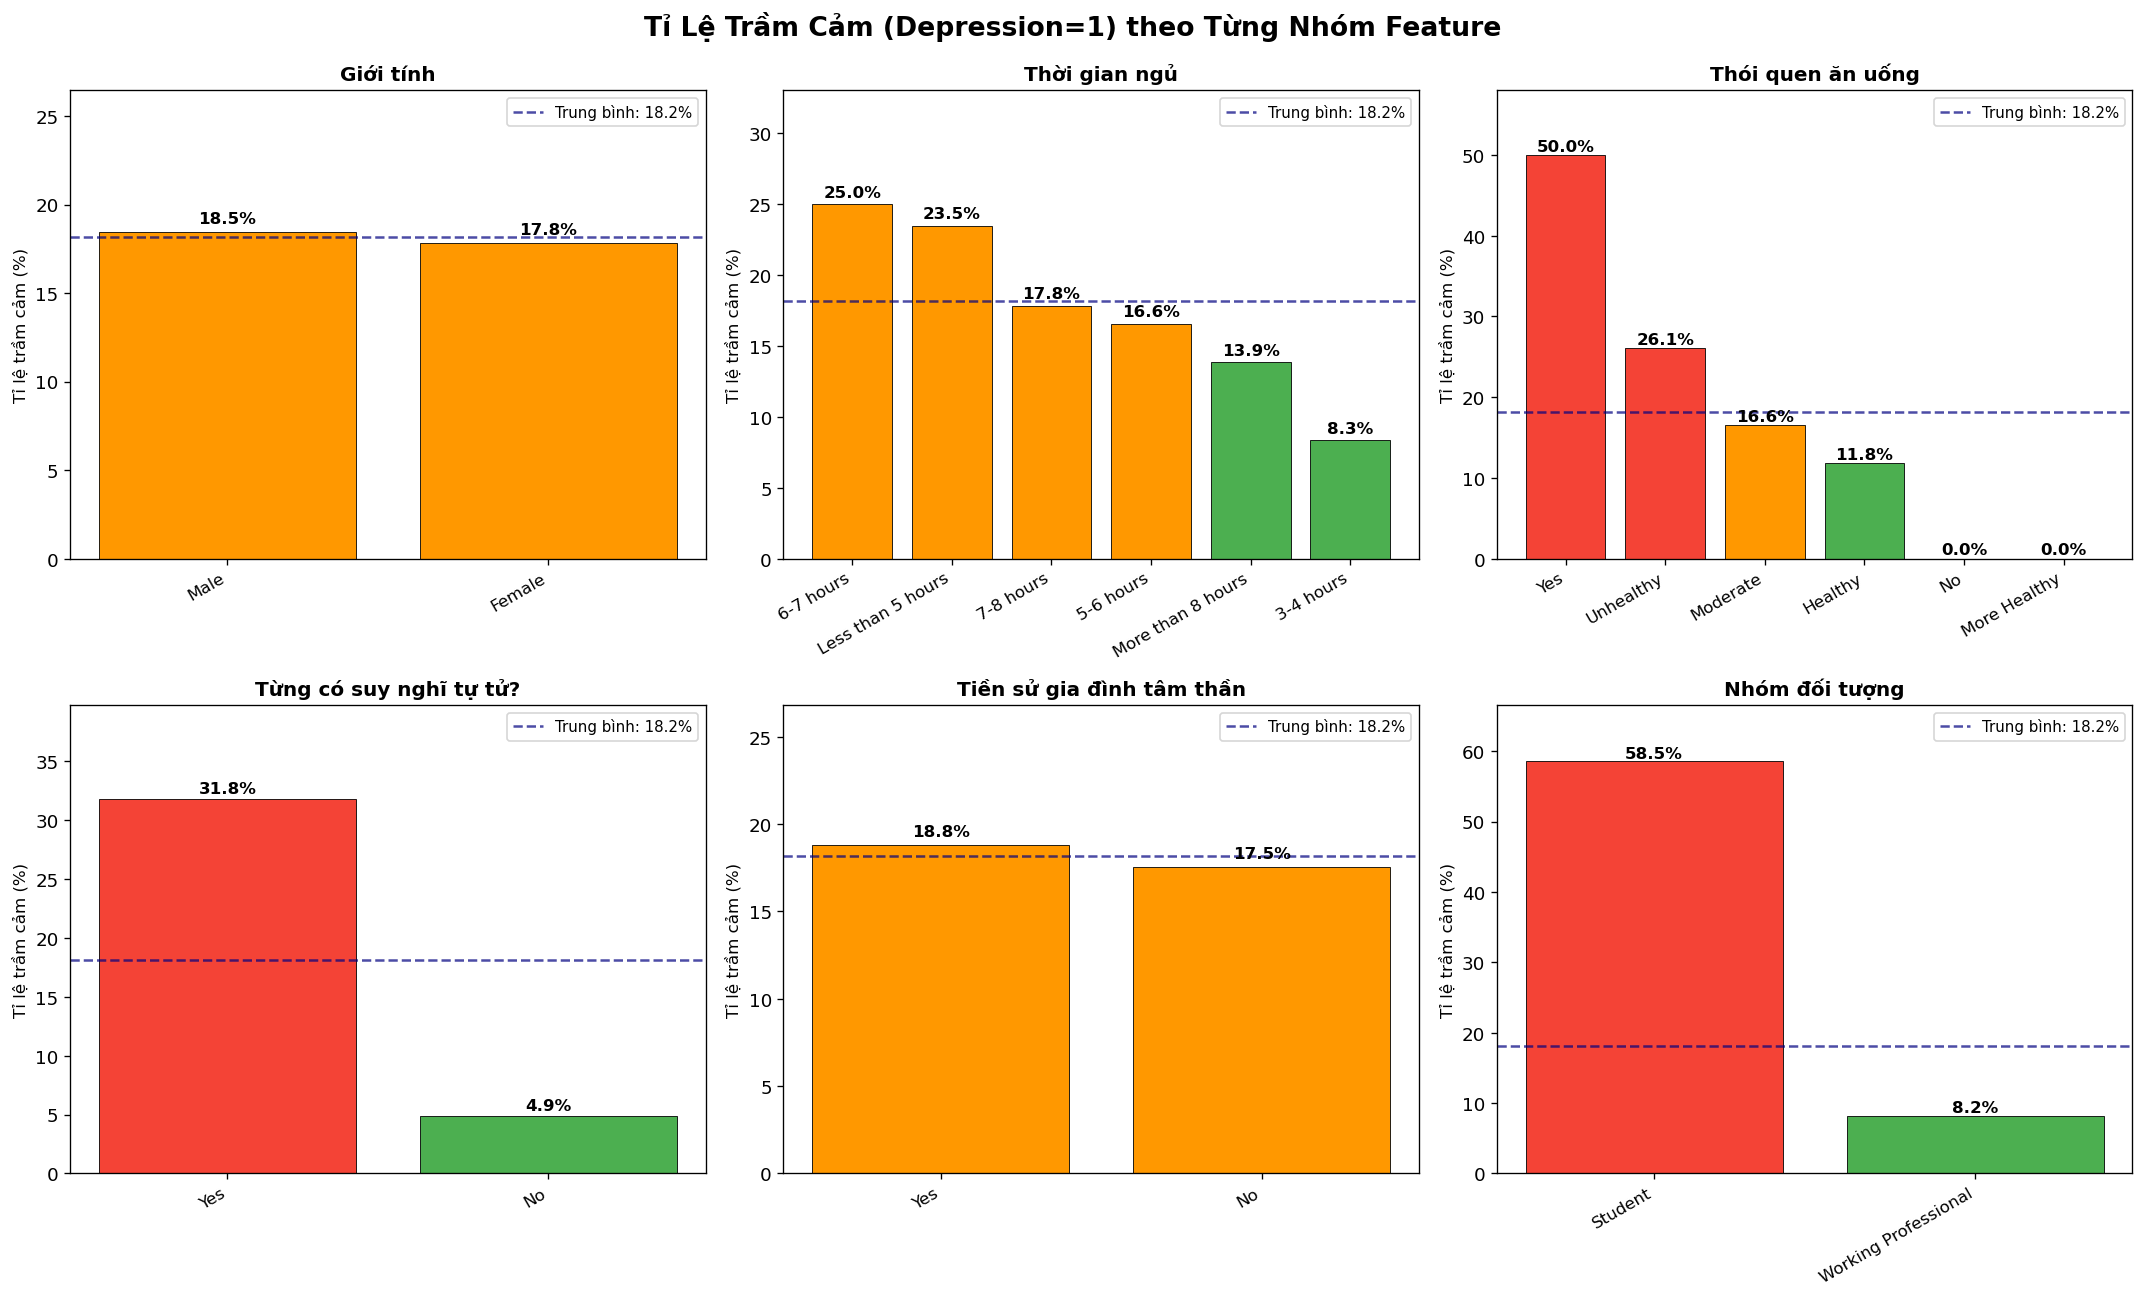

In [ ]:

cat_vs_dep = [
    ('Gender',                               'Giới tính'),
    ('Sleep Duration',                       'Thời gian ngủ'),
    ('Dietary Habits',                       'Thói quen ăn uống'),
    ('Have you ever had suicidal thoughts ?','Từng có suy nghĩ tự tử?'),
    ('Family History of Mental Illness',     'Tiền sử gia đình tâm thần'),
    ('Working Professional or Student',      'Nhóm đối tượng'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Tỉ Lệ Trầm Cảm (Depression=1) theo Từng Nhóm Feature', fontsize=16, fontweight='bold')
axes = axes.flatten()

# Tính giá trị trung bình chung 1 lần để dùng cho tất cả biểu đồ
global_mean = train['Depression'].mean() * 100

for idx, (col, title) in enumerate(cat_vs_dep):
    ax = axes[idx]
    
    # CÁCH KHẮC PHỤC: Chỉ lấy Top 6 giá trị xuất hiện nhiều nhất để vẽ
    # Điều này loại bỏ hoàn toàn các giá trị rác (noise) có tần suất thấp
    top_cats = train[col].value_counts().nlargest(6).index
    subset = train[train[col].isin(top_cats)]
    
    # Tính tỉ lệ trầm cảm trên tập subset đã lọc
    dep_rate = subset.groupby(col)['Depression'].mean().sort_values(ascending=False)
    
    colors_v  = ['#F44336' if v > 0.25 else '#FF9800' if v > 0.15 else '#4CAF50' for v in dep_rate.values]
    bars = ax.bar(range(len(dep_rate)), dep_rate.values * 100, color=colors_v, edgecolor='black', linewidth=0.5)
    
    ax.set_xticks(range(len(dep_rate)))
    # Tăng fontsize và chỉnh góc nghiêng để nhãn trục X dễ nhìn hơn
    ax.set_xticklabels(dep_rate.index, rotation=30, ha='right', fontsize=10)
    
    for j, v in enumerate(dep_rate.values):
        ax.text(j, v*100 + 0.5, f'{v*100:.1f}%', ha='center', fontsize=10, fontweight='bold')
        
    ax.axhline(y=global_mean, color='navy', linestyle='--', alpha=0.7, label=f'Trung bình: {global_mean:.1f}%')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Tỉ lệ trầm cảm (%)', fontsize=10)
    
    # Mở rộng trục Y thêm 1 chút để text phần trăm không bị dính vào viền trên
    ax.set_ylim(0, max(dep_rate.values * 100) + 8)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.subplots_adjust(top=0.92) # Đẩy đồ thị xuống một chút để không đè lên Suptitle
plt.show()

**Phân tích mức độ phân biệt (Discriminative Power) của các biến phân loại:**

Biểu đồ cho thấy mức độ phân biệt rất khác nhau giữa các biến, được chia thành các nhóm mức độ từ mạnh đến yếu như sau:

* **Nhóm phân biệt cực mạnh (Key Predictors):**
    * **Từng có suy nghĩ tự tử? (Suicidal thoughts):** Nhóm có suy nghĩ tự tử có tỉ lệ trầm cảm lên tới **31.8%**, gấp hơn 6 lần so với nhóm Không (**4.9%**). Đây là feature quan trọng bậc nhất về mặt tâm lý học.
    * **Nhóm đối tượng (Student/Working):** Chênh lệch cực kỳ lớn. Nhóm **Student** có tỉ lệ trầm cảm chạm mức **58.5%**, bỏ xa hoàn toàn nhóm Working Professional (chỉ **8.2%**). Đây sẽ là hai features đóng vai trò "gánh" mô hình chính.

* **Nhóm phân biệt tốt (Strong Predictors):**
    * **Thói quen ăn uống (Dietary Habits):** Thể hiện tín hiệu phân loại rõ ràng. Nhóm ăn uống `Unhealthy` (**26.1%**) có tỉ lệ trầm cảm cao gấp hơn 2 lần so với nhóm `Healthy` (**11.8%**). *(Lưu ý: Biểu đồ hiện tại vẫn còn sót các giá trị nhiễu như 'Yes', 'No', 'More Healthy' cần được drop trước khi đưa vào mô hình).*

* **Nhóm phân biệt phức tạp (Complex Predictors):**
    * **Thời gian ngủ (Sleep Duration):** Có sự phân hóa lớn nhưng không tuân theo quy luật U-shape. Nhóm `6-7 hours` và `Less than 5 hours` có rủi ro cao nhất (**25.0%** và **23.5%**), trong khi nhóm ngủ nhiều hơn 8 giờ (`More than 8 hours`) lại có tỉ lệ trầm cảm khá thấp (**13.9%**). 

* **Nhóm phân biệt yếu (Weak Predictors):**
    * **Tiền sử gia đình (Family History):** Có chênh lệch đúng theo logic y khoa (`Yes` **18.8%** > `No` **17.5%**), nhưng mức chênh lệch 1.3% là quá nhỏ.
    * **Giới tính (Gender):** Chênh lệch không đáng kể (`Male` **18.5%** vs `Female` **17.8%**).
    * *Nhận xét:* Nếu đứng độc lập, đây là những features khá yếu do tỉ lệ xoay quanh mức trung bình chung (18.2%). Tuy nhiên, chúng có thể đem lại giá trị khi tạo đặc trưng kết hợp (feature interaction) với các biến khác.

### 4.4.2 Biến số × Depression (Violin Plot)

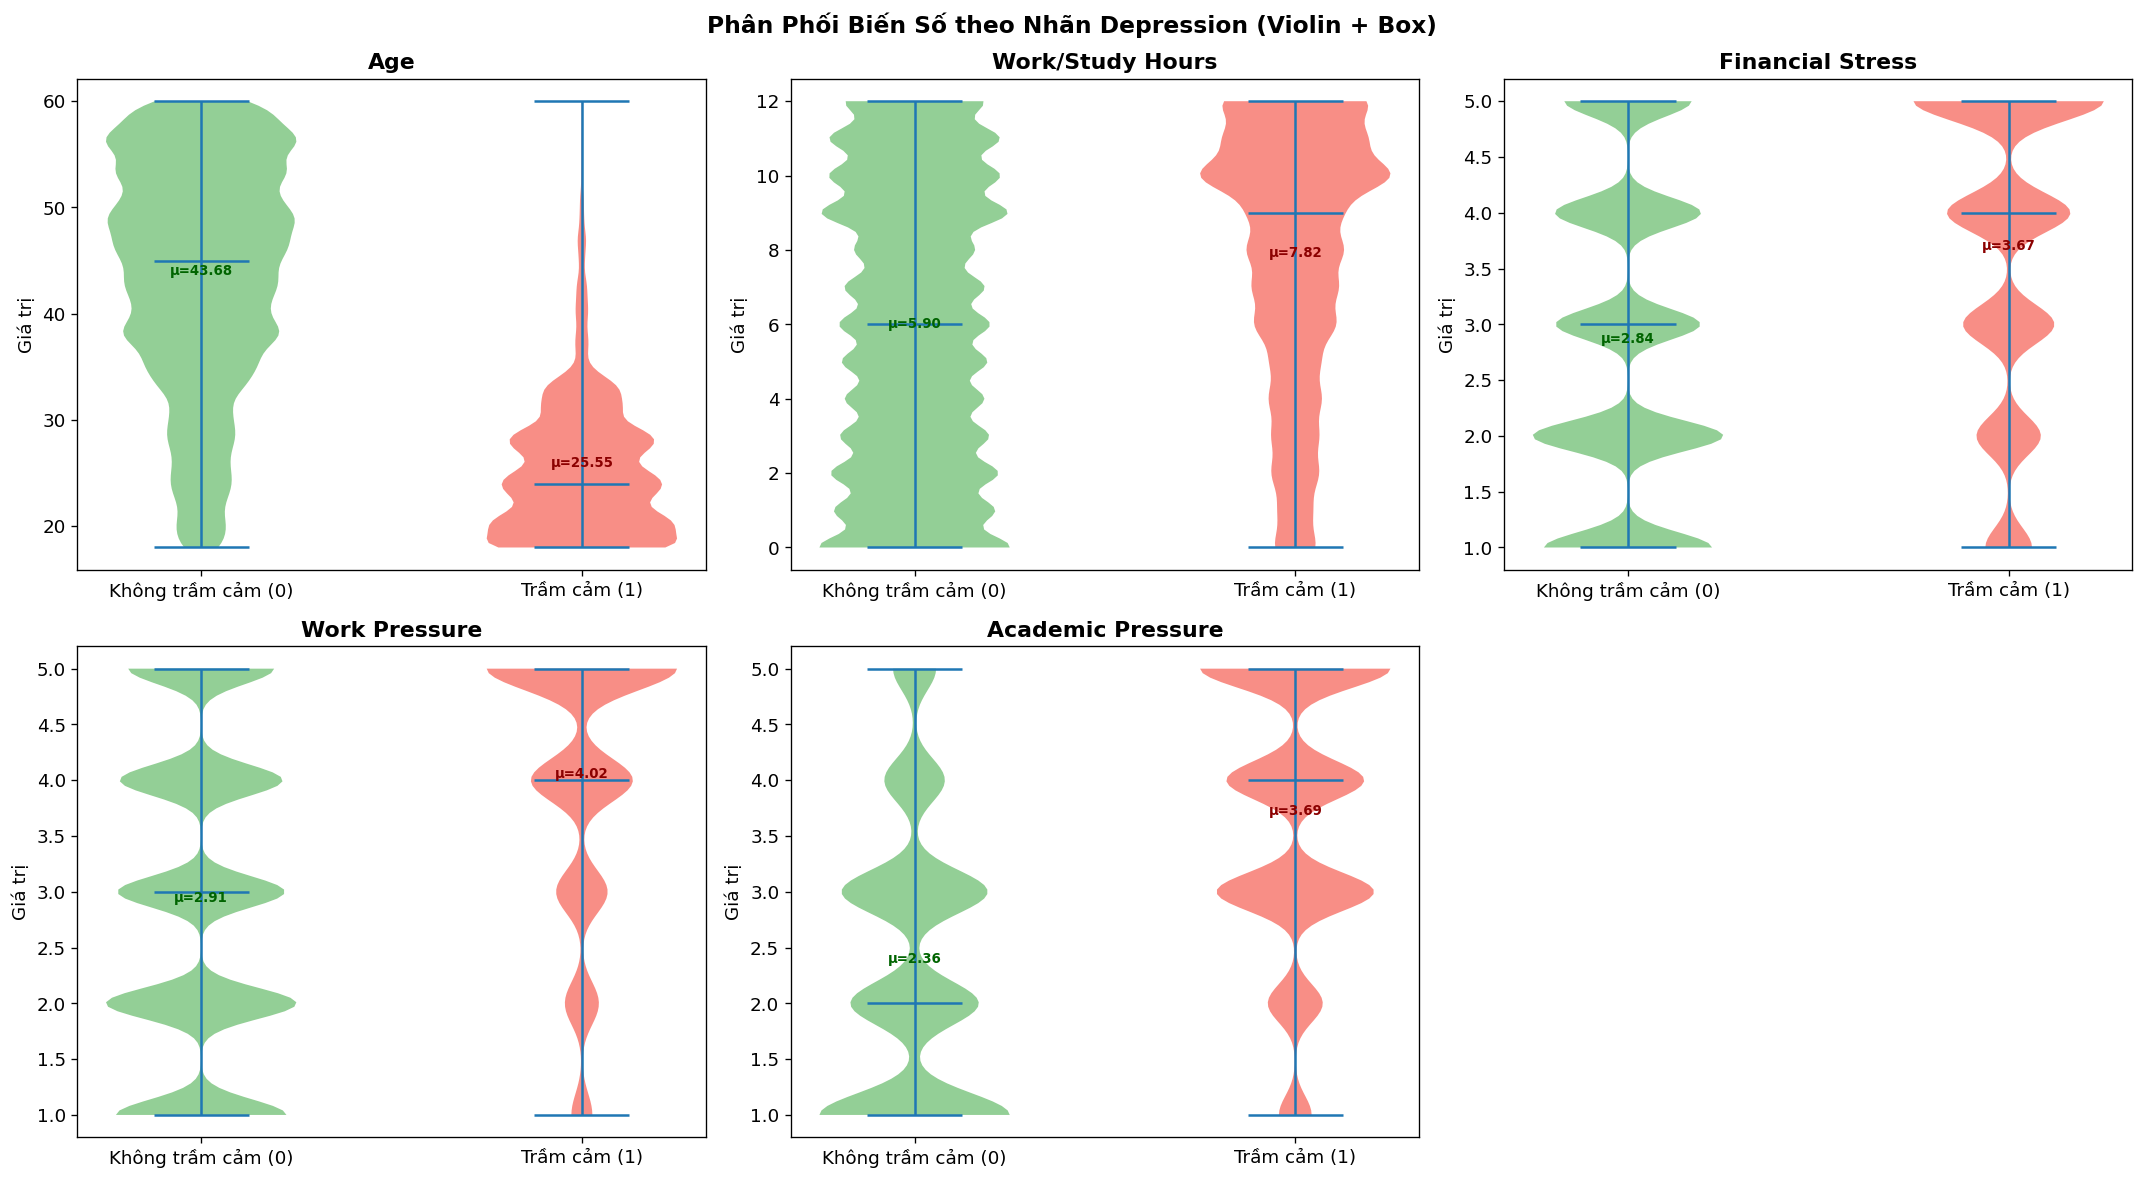

Chênh lệch giá trị trung bình giữa 2 nhóm (Có trầm cảm vs Không trầm cảm):
  Age                           : Không TC = 43.68  |  Có TC = 25.55  |  Δ = -18.13
  Work/Study Hours              : Không TC = 5.90  |  Có TC = 7.82  |  Δ = +1.92
  Financial Stress              : Không TC = 2.84  |  Có TC = 3.67  |  Δ = +0.83
  Work Pressure                 : Không TC = 2.91  |  Có TC = 4.02  |  Δ = +1.11
  Academic Pressure             : Không TC = 2.36  |  Có TC = 3.69  |  Δ = +1.33


In [13]:
num_vs_dep = ['Age', 'Work/Study Hours', 'Financial Stress', 'Work Pressure', 'Academic Pressure']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Phân Phối Biến Số theo Nhãn Depression (Violin + Box)', fontsize=14, fontweight='bold')
axes = axes.flatten()

for idx, col in enumerate(num_vs_dep):
    ax = axes[idx]
    data_0 = train[train['Depression']==0][col].dropna()
    data_1 = train[train['Depression']==1][col].dropna()

    parts = ax.violinplot([data_0, data_1], positions=[0, 1], showmedians=True, showextrema=True)
    parts['bodies'][0].set_facecolor('#4CAF50')
    parts['bodies'][0].set_alpha(0.6)
    parts['bodies'][1].set_facecolor('#F44336')
    parts['bodies'][1].set_alpha(0.6)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Không trầm cảm (0)', 'Trầm cảm (1)'])
    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Giá trị')

    ax.text(0, data_0.mean(), f'μ={data_0.mean():.2f}', ha='center', fontsize=8,
            color='darkgreen', fontweight='bold')
    ax.text(1, data_1.mean(), f'μ={data_1.mean():.2f}', ha='center', fontsize=8,
            color='darkred', fontweight='bold')

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

print("Chênh lệch giá trị trung bình giữa 2 nhóm (Có trầm cảm vs Không trầm cảm):")
for col in num_vs_dep:
    m0 = train[train['Depression']==0][col].mean()
    m1 = train[train['Depression']==1][col].mean()
    diff = m1 - m0
    print(f"  {col:30s}: Không TC = {m0:.2f}  |  Có TC = {m1:.2f}  |  Δ = {diff:+.2f}")


Kết quả chênh lệch mean giữa hai nhóm:

| Feature | Không trầm cảm | Có trầm cảm | Chênh lệch |
|---|---|---|---|
| Age | 43.68 | 25.55 | -18.13 |
| Work/Study Hours | 5.90 | 7.82 | +1.92 |
| Financial Stress | 2.84 | 3.67 | +0.83 |
| Work Pressure | 2.91 | 4.02 | +1.11 |
| Academic Pressure | 2.36 | 3.69 | +1.33 |

**Age** có chênh lệch mean lớn nhất về giá trị tuyệt đối (-18.13): nhóm có trầm cảm trẻ hơn đáng kể (trung bình 25.55 tuổi) so với nhóm không trầm cảm (43.68 tuổi). Tuy nhiên, cần thận trọng trong việc diễn giải: phần lớn mẫu trầm cảm là sinh viên (tỉ lệ 58.55% — sẽ thấy ở mục 4.5), mà sinh viên vốn trẻ hơn người đi làm. Tức là Age bị confounded bởi biến `Working Professional or Student`. Tương quan âm mạnh của Age với Depression có thể chủ yếu phản ánh sự chênh lệch tuổi giữa hai nhóm chứ không phải ảnh hưởng trực tiếp của tuổi.

**Work Pressure** (Δ = +1.11) và **Academic Pressure** (Δ = +1.33) cho thấy nhóm trầm cảm chịu áp lực cao hơn đáng kể. Đây là tín hiệu thực chất và trực tiếp hơn.

**Financial Stress** (Δ = +0.83): nhóm trầm cảm có mức stress tài chính cao hơn. Feature này đặc biệt có giá trị vì nó không bị confounded bởi nhóm Student/Worker — cả hai nhóm đều có giá trị `Financial Stress`.

**Work/Study Hours** (Δ = +1.92): nhóm trầm cảm làm/học nhiều hơn ~2 giờ/ngày. Overload thời gian là yếu tố rủi ro rõ ràng.

Violin plot cũng cho thấy phân phối của hai nhóm chồng nhau đáng kể ở mọi feature — không có feature nào đủ để phân tách hoàn toàn. Điều này bình thường với dữ liệu thực tế và là lý do cần dùng mô hình học máy tổng hợp nhiều feature cùng lúc.


## 4.5 Phân tích theo Nhóm: Student vs Working Professional

In [14]:
student = train[train['Working Professional or Student'] == 'Student']
worker  = train[train['Working Professional or Student'] == 'Working Professional']

print(f"Số lượng Sinh viên         : {len(student):,} ({len(student)/len(train)*100:.1f}%)")
print(f"Số lượng Người đi làm      : {len(worker):,}  ({len(worker)/len(train)*100:.1f}%)")
print()
print(f"Tỉ lệ trầm cảm – Sinh viên : {student['Depression'].mean()*100:.2f}%")
print(f"Tỉ lệ trầm cảm – Đi làm   : {worker['Depression'].mean()*100:.2f}%")
print(f"Tỉ lệ trầm cảm – Tổng     : {train['Depression'].mean()*100:.2f}%")


Số lượng Sinh viên         : 27,901 (19.8%)
Số lượng Người đi làm      : 112,799  (80.2%)

Tỉ lệ trầm cảm – Sinh viên : 58.55%
Tỉ lệ trầm cảm – Đi làm   : 8.18%
Tỉ lệ trầm cảm – Tổng     : 18.17%


Đây là phát hiện quan trọng nhất trong toàn bộ EDA.

Tỉ lệ trầm cảm ở nhóm **sinh viên là 58.55%**, trong khi ở nhóm **người đi làm chỉ là 8.18%**. Chênh lệch hơn 7 lần. Đây không phải là sự khác biệt nhỏ mà là sự phân tách gần như hoàn toàn về bản chất dữ liệu.

Con số này có một số hàm ý quan trọng:

Thứ nhất, `Working Professional or Student` thực tế là **một trong các feature quan trọng nhất** của mô hình, dù correlation Pearson với Depression đơn lẻ không phản ánh hết.

Thứ hai, nếu không tách biệt phân tích, các mô hình sẽ học ngầm định rằng "sinh viên → có khả năng trầm cảm cao" và "người đi làm → ít khả năng trầm cảm". Điều này có thể dẫn đến mô hình chủ yếu dựa vào biến này thay vì học các pattern thực chất từ stress, sleep, satisfaction.

Thứ ba, các biến như Age (trẻ → trầm cảm), Work Pressure, Academic Pressure khi phân tích trên toàn dataset đều bị confounded bởi sự phân tách này. Ví dụ, tương quan Age-Depression (-0.565 ở mục 4.6) phần lớn đến từ việc sinh viên vừa trẻ vừa có tỉ lệ trầm cảm cao — không phải Age trực tiếp gây ra.


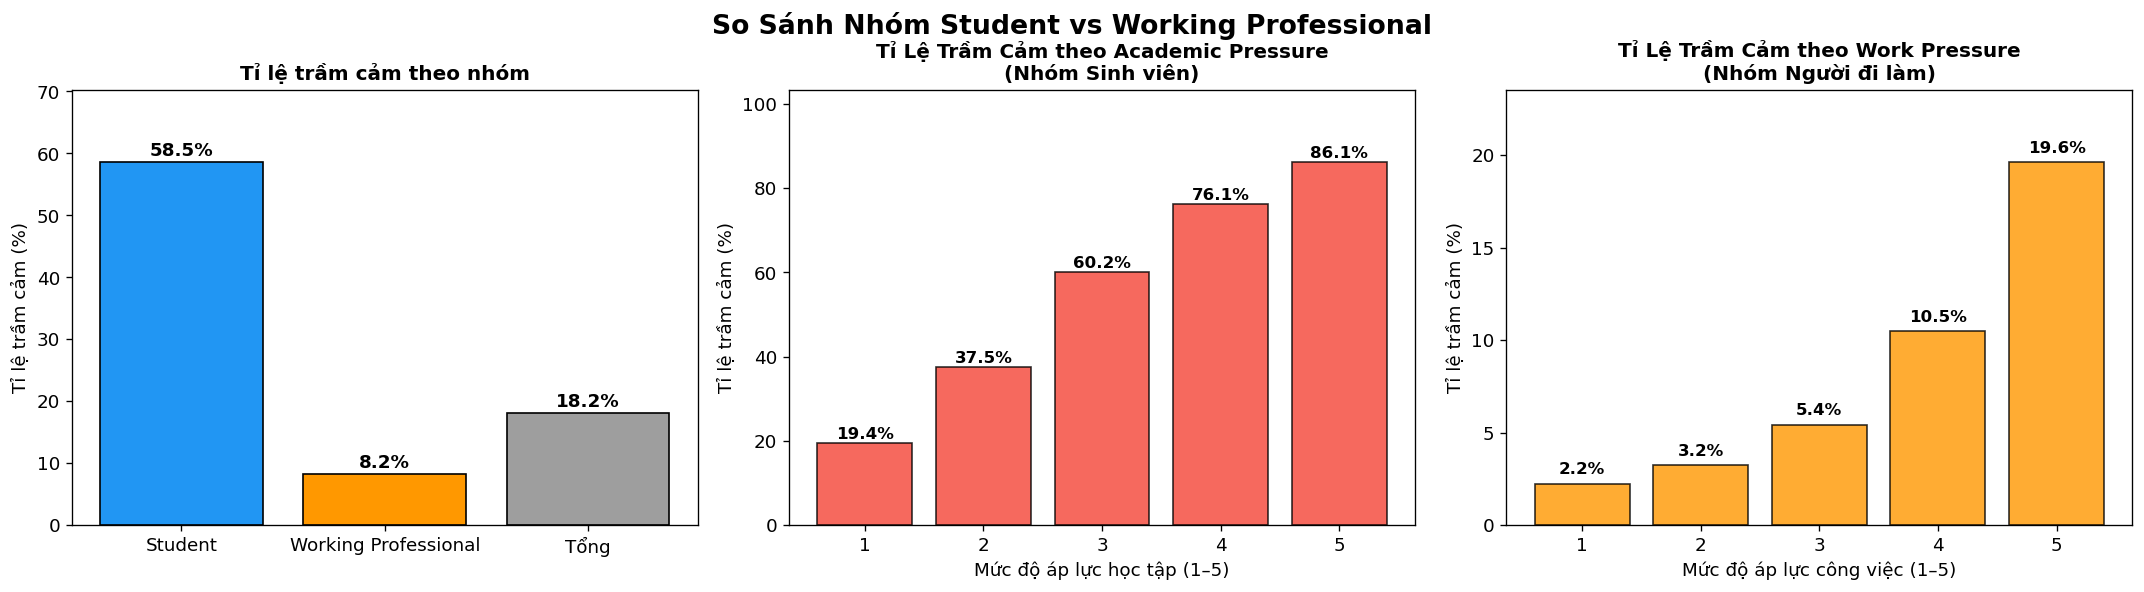

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('So Sánh Nhóm Student vs Working Professional', fontsize=16, fontweight='bold')

# ==========================================
# BIỂU ĐỒ 1: Tỉ lệ trầm cảm tổng quan
# ==========================================
groups = ['Student', 'Working Professional', 'Tổng']
rates  = [student['Depression'].mean()*100,
          worker['Depression'].mean()*100,
          train['Depression'].mean()*100]
colors_g = ['#2196F3', '#FF9800', '#9E9E9E']

axes[0].bar(groups, rates, color=colors_g, edgecolor='black')
for i, v in enumerate(rates):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=11)
axes[0].set_title('Tỉ lệ trầm cảm theo nhóm', fontweight='bold', fontsize=12)
axes[0].set_ylabel('Tỉ lệ trầm cảm (%)')
axes[0].set_ylim(0, max(rates)*1.2) # Mở rộng trục Y một chút để chữ không chạm đỉnh

# ==========================================
# BIỂU ĐỒ 2: Áp lực học tập (Sinh viên)
# ==========================================
ax2 = axes[1]
# Tính tỉ lệ trầm cảm tại từng mức độ áp lực (1, 2, 3, 4, 5)
stu_ap_rate = student.groupby('Academic Pressure')['Depression'].mean() * 100

# Vẽ biểu đồ cột rời rạc (Bar chart) thay vì Histogram
bars2 = ax2.bar(stu_ap_rate.index, stu_ap_rate.values, color='#F44336', edgecolor='black', alpha=0.8)
for i, v in zip(stu_ap_rate.index, stu_ap_rate.values):
    ax2.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=10)

ax2.set_title('Tỉ Lệ Trầm Cảm theo Academic Pressure\n(Nhóm Sinh viên)', fontweight='bold', fontsize=12)
ax2.set_xlabel('Mức độ áp lực học tập (1–5)')
ax2.set_ylabel('Tỉ lệ trầm cảm (%)')
ax2.set_xticks(range(1, 6)) # Ép trục X chỉ hiện số nguyên 1, 2, 3, 4, 5
ax2.set_ylim(0, max(stu_ap_rate.values)*1.2)

# ==========================================
# BIỂU ĐỒ 3: Áp lực công việc (Người đi làm)
# ==========================================
ax3 = axes[2]
# Tính tỉ lệ trầm cảm tại từng mức độ áp lực (1, 2, 3, 4, 5)
work_wp_rate = worker.groupby('Work Pressure')['Depression'].mean() * 100

bars3 = ax3.bar(work_wp_rate.index, work_wp_rate.values, color='#FF9800', edgecolor='black', alpha=0.8)
for i, v in zip(work_wp_rate.index, work_wp_rate.values):
    ax3.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=10)

ax3.set_title('Tỉ Lệ Trầm Cảm theo Work Pressure\n(Nhóm Người đi làm)', fontweight='bold', fontsize=12)
ax3.set_xlabel('Mức độ áp lực công việc (1–5)')
ax3.set_ylabel('Tỉ lệ trầm cảm (%)')
ax3.set_xticks(range(1, 6)) # Ép trục X chỉ hiện số nguyên
ax3.set_ylim(0, max(work_wp_rate.values)*1.2)

plt.tight_layout()
plt.subplots_adjust(top=0.85) # Hạ thấp đồ thị xuống để không đè lên Title tổng
plt.show()

**Nhận xét xu hướng từ biểu đồ:**
Biểu đồ Tỉ lệ trầm cảm theo từng mức áp lực cho thấy một pattern (xu hướng) cực kỳ rõ ràng và tuyến tính: **Áp lực càng cao, rủi ro trầm cảm càng lớn.**
* **Nhóm Sinh viên:** Tỉ lệ trầm cảm tăng phi mã từ 19.4% (ở mức áp lực 1) lên mức đáng báo động 86.1% (ở mức áp lực 5).
* **Nhóm Người đi làm:** Dù nền trầm cảm thấp, nhưng khi áp lực đạt mức 5, rủi ro trầm cảm cũng vọt lên 19.6% (cao gấp gần 9 lần so với mức áp lực 1 là 2.2%).

**Đề xuất chiến lược Feature Engineering và Modeling:**
Do sự khác biệt quá lớn về mặt cấu trúc và tỉ lệ nền giữa hai nhóm đối tượng, đây là các bước xử lý tối ưu:
1. **Gộp biến (Handling Structural Missing Data):** Tạo biến chung `Unified_Pressure` (gộp `Academic Pressure` và `Work Pressure`) và `Unified_Satisfaction` (gộp `Study Satisfaction` và `Job Satisfaction`). Việc này giúp loại bỏ hoàn toàn các giá trị NaN sinh ra do tính chất nghề nghiệp, đồng thời giữ nguyên vẹn thang đo 1-5 của mức độ áp lực/hài lòng.
2. **Tiếp cận Đa mô hình (Two-model Approach):** Cân nhắc không train một mô hình duy nhất cho toàn bộ dữ liệu. Thay vào đó, xây dựng hai Pipeline mô hình riêng biệt: một cho Student và một cho Working Professional. Điều này giúp mô hình bắt được các pattern đặc thù của từng nhóm mà không bị nhiễu bởi nhóm còn lại, tối ưu hóa triệt để hiệu suất dự đoán.

## 4.6 Ma Trận Tương Quan (Correlation Heatmap)

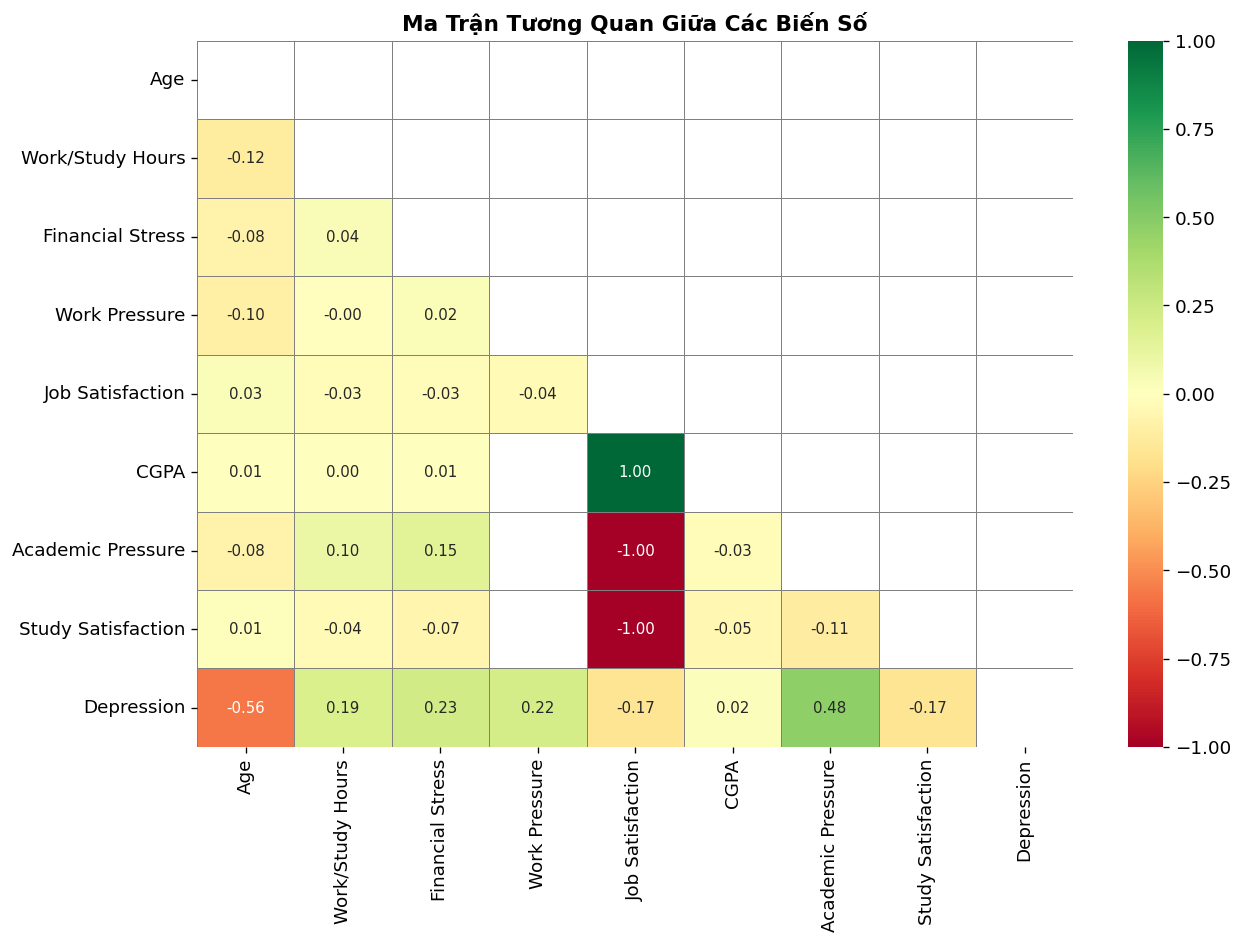


Tương quan từng feature với Depression (sắp xếp theo |r|):
  Age                           : r = -0.565
  Academic Pressure             : r = +0.475
  Financial Stress              : r = +0.227
  Work Pressure                 : r = +0.217
  Work/Study Hours              : r = +0.192
  Job Satisfaction              : r = -0.169
  Study Satisfaction            : r = -0.168
  CGPA                          : r = +0.022


In [ ]:
# Chọn biến số có ý nghĩa (bỏ id)
num_corr_cols = ['Age', 'Work/Study Hours', 'Financial Stress',
                 'Work Pressure', 'Job Satisfaction',
                 'CGPA', 'Academic Pressure', 'Study Satisfaction',
                 'Depression']

corr_matrix = train[num_corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, linewidths=0.5, linecolor='grey',
            annot_kws={'size': 9}, ax=ax)
ax.set_title('Ma Trận Tương Quan Giữa Các Biến Số', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nTương quan từng feature với Depression (sắp xếp theo |r|):")
dep_corr = corr_matrix['Depression'].drop('Depression').abs().sort_values(ascending=False)
for feat, val in dep_corr.items():
    sign = '+' if corr_matrix['Depression'][feat] > 0 else '-'
    print(f"  {feat:30s}: r = {sign}{val:.3f}")


**Kết quả tương quan tuyến tính (Pearson) với Depression:**

| Feature | r | Chiều | Nhận xét |
|---|---|---|---|
| Age | -0.565 | Âm mạnh | Confounding effect (Nhiễu nhóm tuổi do Student/Worker) |
| Academic Pressure | +0.475 | Dương mạnh | Tín hiệu thực chất ở nhóm Sinh viên |
| Financial Stress | +0.227 | Dương trung bình | Tín hiệu tốt, áp dụng cho cả 2 nhóm |
| Work Pressure | +0.217 | Dương trung bình | Tín hiệu thực chất ở nhóm Người đi làm |
| Work/Study Hours | +0.192 | Dương nhẹ | Có rủi ro khi overwork |
| Job Satisfaction | -0.169 | Âm nhẹ | Hài lòng thấp -> Dễ trầm cảm hơn |
| Study Satisfaction| -0.168 | Âm nhẹ | Tương tự Job Satisfaction |
| CGPA | +0.022 | Rất yếu | Điểm số đơn thuần không dự đoán được trầm cảm |

**Nhận xét chi tiết:**

1. **Vấn đề của biến `Age` (-0.565):** Mặc dù có hệ số cao nhất, nhưng đây chủ yếu là "confounding effect" (tác động nhiễu) của biến phân nhóm đối tượng. Tập sinh viên có rủi ro trầm cảm cực cao (58.5%) và dĩ nhiên họ trẻ tuổi hơn nhóm đi làm. Tương quan âm mạnh này phản ánh sự chênh lệch tuổi giữa 2 nhóm chứ không hẳn là quan hệ nhân quả. Các mô hình Tree-based sẽ tự động bắt được điều này, nhưng nếu dùng Logistic Regression cần cẩn trọng khi diễn giải hệ số.
2. **Dấu hiệu Structural Missing Data trên Heatmap:** Quan sát các ô giao nhau giữa biến Sinh viên (`CGPA`, `Academic Pressure`) và biến Người đi làm (`Job Satisfaction`), xuất hiện các ô trống (NaN) hoặc giá trị nhiễu tuyệt đối (1.00 / -1.00). Điều này xảy ra do hai nhóm tính năng này loại trừ lẫn nhau (mutually exclusive). Đây là minh chứng rõ ràng nhất cho việc bắt buộc phải tạo biến gộp `Unified_Pressure` và `Unified_Satisfaction` trước khi đưa vào mô hình để tránh lỗi toán học.
3. **Multicollinearity (Đa cộng tuyến):** Tương quan giữa `Academic Pressure` và `Study Satisfaction` (-0.11), hoặc `Work Pressure` và `Job Satisfaction` (-0.04) là rất yếu. Do đó, không có rủi ro đa cộng tuyến đáng kể giữa các features nội bộ.
4. **Giới hạn của Pearson:** Heatmap này chỉ thể hiện tương quan tuyến tính. Các biến phân loại cực mạnh (như `Suicidal Thoughts`, `Sleep Duration`) hoàn toàn vắng mặt. Việc đánh giá Feature Importance bằng mô hình học máy (như Random Forest, XGBoost) ở bước sau sẽ cung cấp bức tranh toàn diện hơn.

## 4.7 Phân tích Outliers

Phát hiện Outliers bằng phương pháp IQR (1.5×IQR):
Feature                            Q1     Q3    IQR    Lower    Upper   # Outliers       %
-------------------------------------------------------------------------------------
  Age                            29.0   51.0   22.0     -4.0     84.0            0   0.00%
  Work/Study Hours                3.0   10.0    7.0     -7.5     20.5            0   0.00%
  Financial Stress                2.0    4.0    2.0     -1.0      7.0            0   0.00%
  Work Pressure                   2.0    4.0    2.0     -1.0      7.0            0   0.00%
  Academic Pressure               2.0    4.0    2.0     -1.0      7.0            0   0.00%


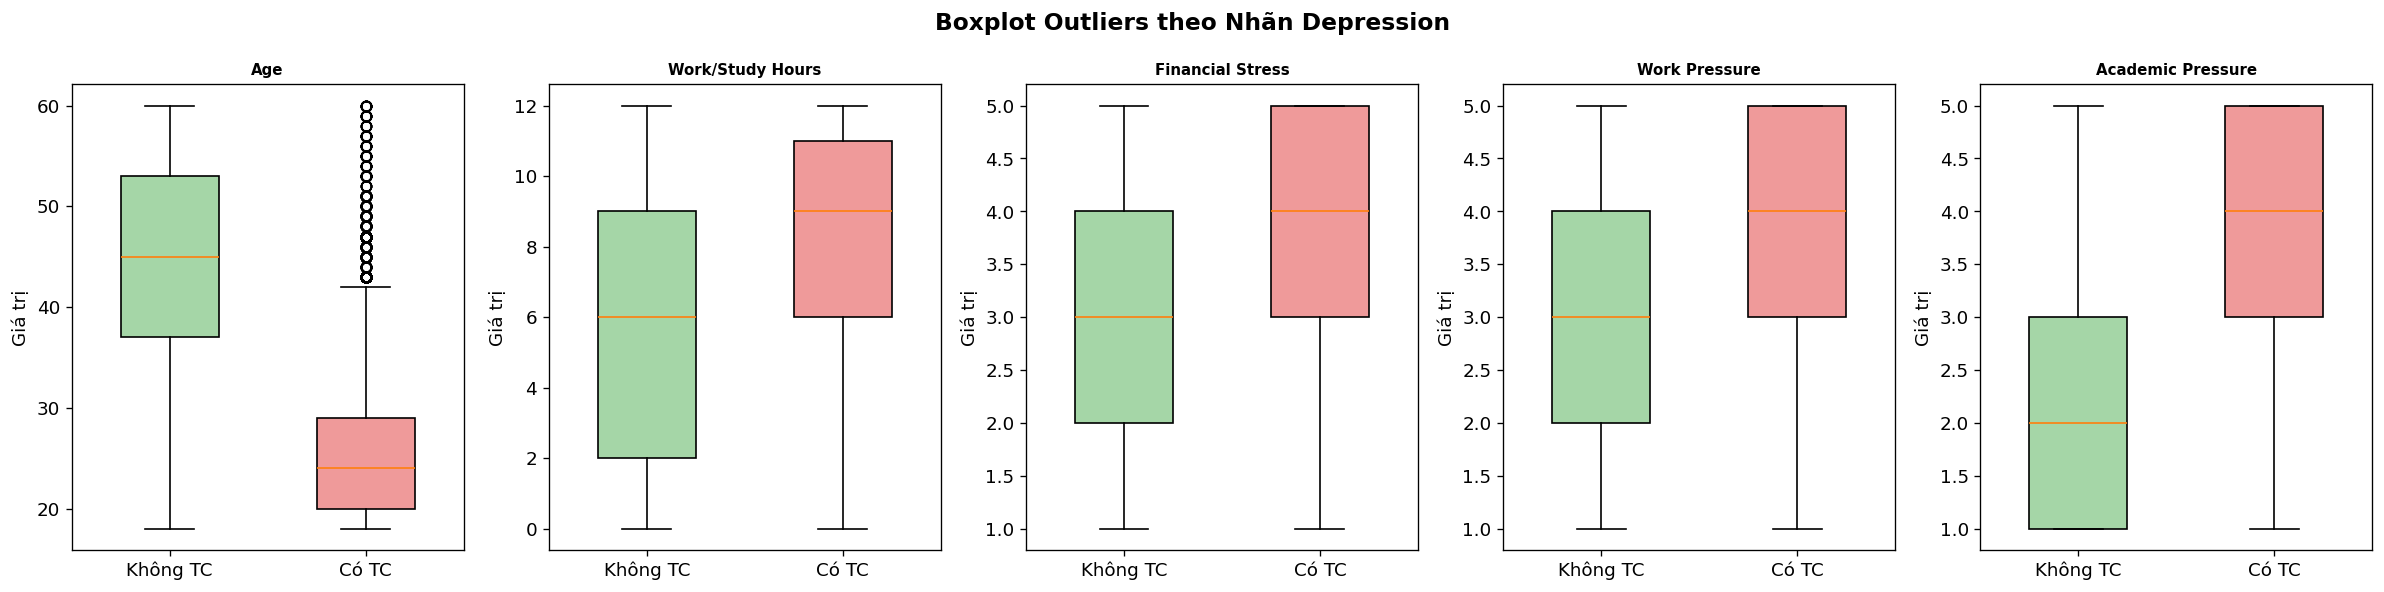

In [ ]:
num_check = ['Age', 'Work/Study Hours', 'Financial Stress', 'Work Pressure', 'Academic Pressure']

print("Phát hiện Outliers bằng phương pháp IQR (1.5×IQR):")
print(f"{'Feature':<30} {'Q1':>6} {'Q3':>6} {'IQR':>6} {'Lower':>8} {'Upper':>8} {'# Outliers':>12} {'%':>7}")
print("-"*85)
for col in num_check:
    data = train[col].dropna()
    Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
    IQR    = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out  = ((data < lower) | (data > upper)).sum()
    print(f"  {col:<28} {Q1:>6.1f} {Q3:>6.1f} {IQR:>6.1f} {lower:>8.1f} {upper:>8.1f} {n_out:>12,} {n_out/len(data)*100:>6.2f}%")

fig, axes = plt.subplots(1, len(num_check), figsize=(20, 5))
fig.suptitle('Boxplot Outliers theo Nhãn Depression', fontsize=14, fontweight='bold')

for i, col in enumerate(num_check):
    ax = axes[i]
    data_0 = train[train['Depression']==0][col].dropna()
    data_1 = train[train['Depression']==1][col].dropna()
    bp = ax.boxplot([data_0, data_1], patch_artist=True,
                    labels=['Không TC', 'Có TC'], widths=0.5)
    bp['boxes'][0].set_facecolor('#A5D6A7')
    bp['boxes'][1].set_facecolor('#EF9A9A')
    ax.set_title(col, fontweight='bold', fontsize=9)
    ax.set_ylabel('Giá trị')

plt.tight_layout()
plt.show()


**Phát hiện Outliers bằng phương pháp IQR (1.5×IQR):**

| Feature | Q1 | Q3 | IQR | Lower | Upper | # Outliers | % |
|---|---|---|---|---|---|---|---|
| Age | 29.0 | 51.0 | 22.0 | -4.0 | 84.0 | 0 | 0.00% |
| Work/Study Hours | 3.0 | 10.0 | 7.0 | -7.5 | 20.5 | 0 | 0.00% |
| Financial Stress | 2.0 | 4.0 | 2.0 | -1.0 | 7.0 | 0 | 0.00% |
| Work Pressure | 2.0 | 4.0 | 2.0 | -1.0 | 7.0 | 0 | 0.00% |
| Academic Pressure| 2.0 | 4.0 | 2.0 | -1.0 | 7.0 | 0 | 0.00% |

**Nhận xét phân tích Outliers:**

1. **Global Outliers (Toàn cục):** Kết quả kiểm tra IQR trên toàn bộ tập dữ liệu cho thấy tất cả 5 biến số đều có 0 outlier (0.00%). Đây là đặc trưng của dữ liệu có giới hạn biên chặt chẽ (thang 1–5, 0–12 giờ, 18–60 tuổi) nên các giá trị không thể vượt quá ngưỡng Upper/Lower Bounds toàn cục. Do đó, **không cần thực hiện các kỹ thuật clipping hay remove outliers** cho các biến số này.
2. **Group-wise Outliers (Cục bộ theo nhóm) ở biến Age:** Mặc dù không có outlier toàn cục, nhưng nhìn vào Boxplot của biến `Age`, ta thấy một chuỗi các điểm dị biệt (vòng tròn) ở nhóm Có Trầm Cảm (màu đỏ) từ mốc >42 tuổi. Nguyên nhân là do độ tuổi của nhóm trầm cảm tập trung quá dày đặc ở phân khúc thanh niên/sinh viên (Q3 chỉ ~29 tuổi), khiến những người trung niên/lớn tuổi mắc trầm cảm trở thành những "outlier cục bộ" so với chính nhóm bệnh nhân. Điều này tiếp tục củng cố luận điểm `Age` bị ảnh hưởng nặng bởi biến phân nhóm Student/Worker.
3. **Phân phối Áp lực:** Median của `Work Pressure` và `Academic Pressure` ở nhóm trầm cảm (cột đỏ) đều bị đẩy lên cao hơn rõ rệt so với nhóm không trầm cảm, xác nhận lại xu hướng áp lực cao sinh ra rủi ro trầm cảm lớn.
4. **Lưu ý quan trọng về Data Quality:** Việc biến số (Numerical) không có outlier không đồng nghĩa với việc dữ liệu sạch hoàn toàn. Các biến phân loại (Categorical) như `Dietary Habits`, `Sleep Duration` vẫn chứa nhiều giá trị rác (noise) dạng chuỗi. Đây là lỗi nhập liệu cần được xử lý riêng biệt trong phần Data Cleaning, không liên quan đến Outlier thống kê.

## 4.8 So Sánh Phân Phối Train vs Test (Data Shift Check)

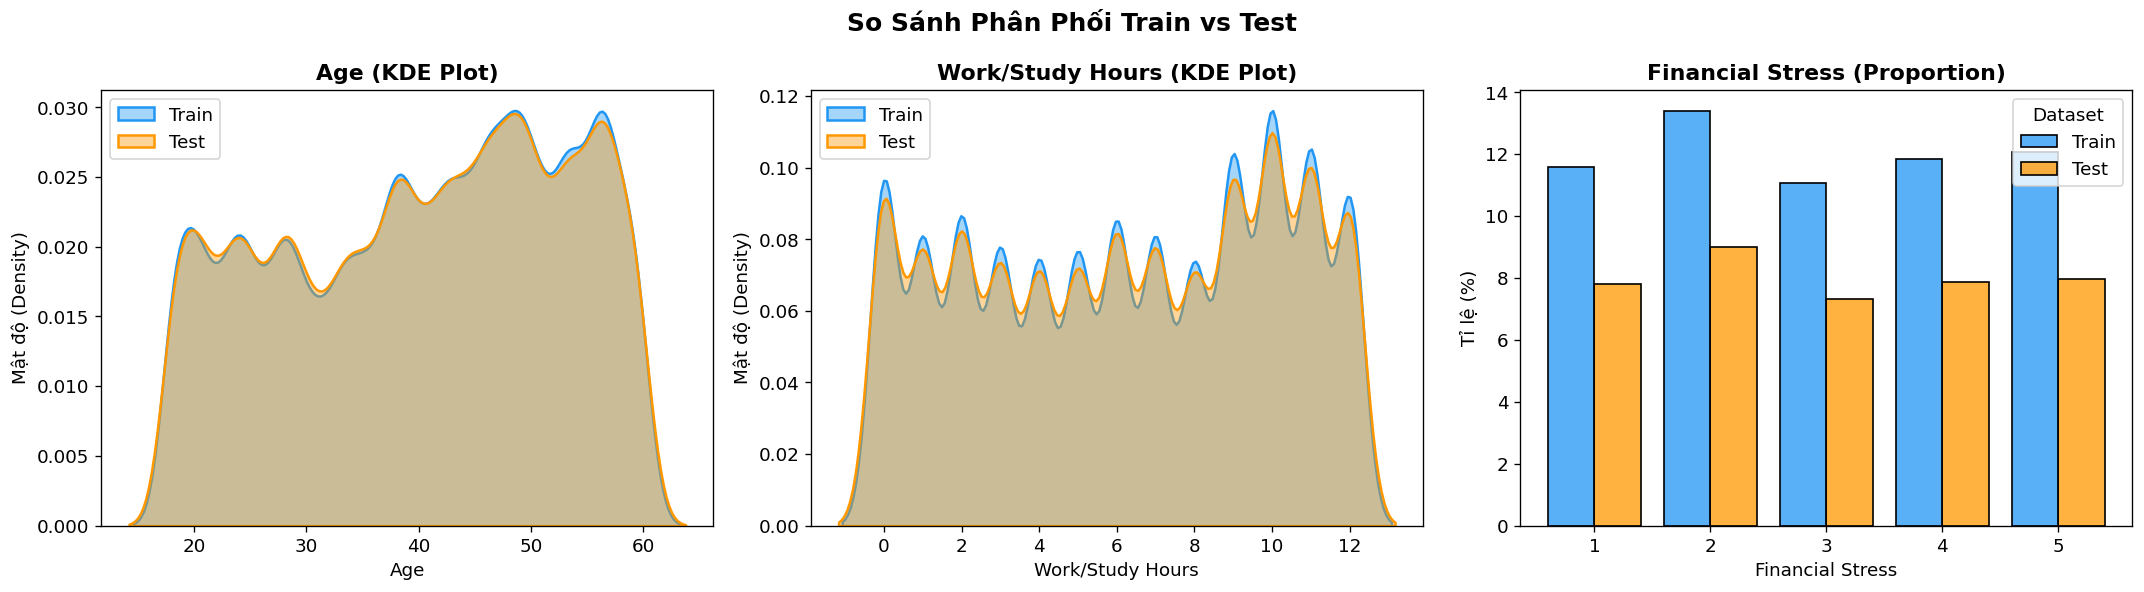

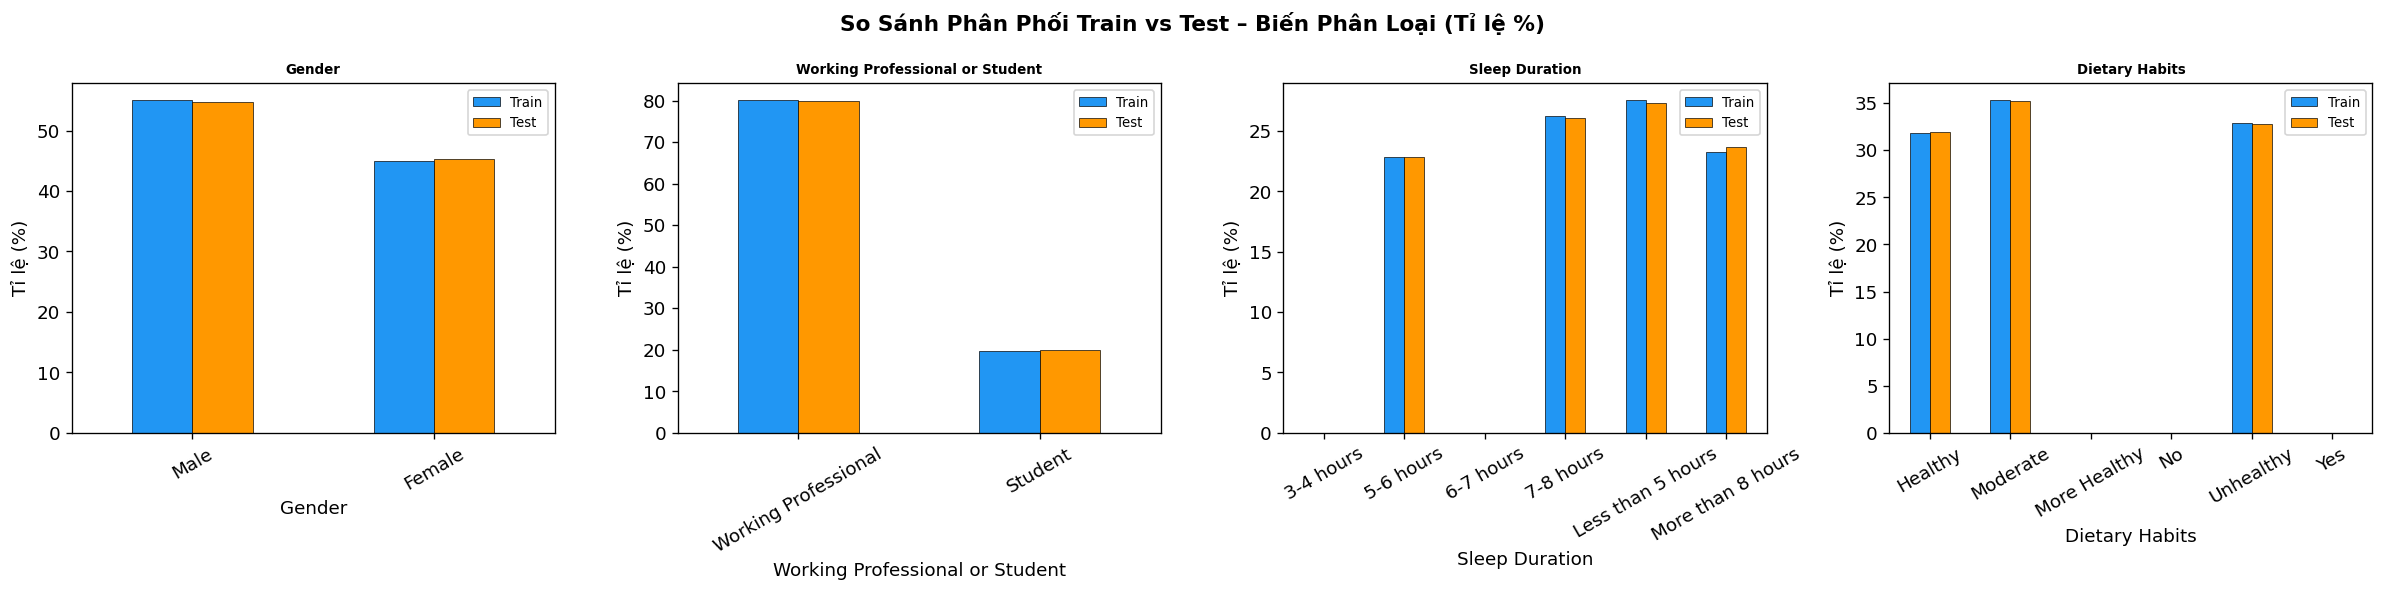


Missing Values trong tập TEST:
                    Số lượng missing  Tỉ lệ (%)
CGPA                           75034      79.99
Academic Pressure              75033      79.99
Study Satisfaction             75033      79.99
Profession                     24632      26.26
Work Pressure                  18778      20.02
Job Satisfaction               18774      20.01
Dietary Habits                     5       0.01
Degree                             2       0.00


In [ ]:
# So sánh phân phối biến số: train vs test
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('So Sánh Phân Phối Train vs Test', fontsize=15, fontweight='bold')

# 1. Biểu đồ Age (Dùng KDE vuốt cong)
sns.kdeplot(data=train, x='Age', ax=axes[0], fill=True, color='#2196F3', label='Train', alpha=0.4, linewidth=1.5)
sns.kdeplot(data=test, x='Age', ax=axes[0], fill=True, color='#FF9800', label='Test', alpha=0.4, linewidth=1.5)
axes[0].set_title('Age (KDE Plot)', fontweight='bold')
axes[0].set_ylabel('Mật độ (Density)')
axes[0].legend()

# 2. Biểu đồ Work/Study Hours (Dùng KDE vuốt cong)
sns.kdeplot(data=train, x='Work/Study Hours', ax=axes[1], fill=True, color='#2196F3', label='Train', alpha=0.4, linewidth=1.5)
sns.kdeplot(data=test, x='Work/Study Hours', ax=axes[1], fill=True, color='#FF9800', label='Test', alpha=0.4, linewidth=1.5)
axes[1].set_title('Work/Study Hours (KDE Plot)', fontweight='bold')
axes[1].set_ylabel('Mật độ (Density)')
axes[1].legend()

# 3. Biểu đồ Financial Stress (Biến rời rạc -> Dùng Grouped Histplot tỷ lệ %)
# Tạo 1 dataframe tạm để Seaborn tự động chia cột song song
tmp_train = pd.DataFrame({'Financial Stress': train['Financial Stress'].dropna(), 'Dataset': 'Train'})
tmp_test  = pd.DataFrame({'Financial Stress': test['Financial Stress'].dropna(), 'Dataset': 'Test'})
combo_df  = pd.concat([tmp_train, tmp_test])

sns.histplot(
    data=combo_df, 
    x='Financial Stress', 
    hue='Dataset', 
    multiple='dodge',  # Tách 2 cột song song
    stat='percent',    # Tính theo % thay vì số lượng
    discrete=True,     # Bắt buộc căn giữa các mốc 1, 2, 3, 4, 5
    shrink=0.8,        # Thu gọn bề ngang cột cho đẹp
    palette=['#2196F3', '#FF9800'],
    ax=axes[2]
)
axes[2].set_title('Financial Stress (Proportion)', fontweight='bold')
axes[2].set_ylabel('Tỉ lệ (%)')
axes[2].set_xticks([1, 2, 3, 4, 5]) # Ép hiện số nguyên

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

# So sánh biến phân loại
cat_compare = ['Gender', 'Working Professional or Student', 'Sleep Duration', 'Dietary Habits']

fig, axes = plt.subplots(1, len(cat_compare), figsize=(20, 5))
fig.suptitle('So Sánh Phân Phối Train vs Test – Biến Phân Loại (Tỉ lệ %)', fontsize=13, fontweight='bold')

for i, col in enumerate(cat_compare):
    ax = axes[i]
    train_pct = (train[col].value_counts(normalize=True) * 100).head(5)
    test_pct  = (test[col].value_counts(normalize=True)  * 100).head(5)
    combined  = pd.DataFrame({'Train': train_pct, 'Test': test_pct}).fillna(0)
    combined.plot(kind='bar', ax=ax, color=['#2196F3','#FF9800'], edgecolor='black', linewidth=0.4)
    ax.set_title(col, fontsize=8, fontweight='bold')
    ax.set_ylabel('Tỉ lệ (%)')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Missing values trong test
print("\nMissing Values trong tập TEST:")
missing_test = test.isnull().sum()
missing_test = missing_test[missing_test > 0]
if len(missing_test) > 0:
    missing_test_df = pd.DataFrame({
        'Số lượng missing': missing_test,
        'Tỉ lệ (%)': (missing_test / len(test) * 100).round(2)
    }).sort_values('Số lượng missing', ascending=False)
    print(missing_test_df.to_string())
else:
    print("  Không có missing values trong test set.")


**Đánh giá Phân phối Train vs Test (Data Shift Check)**

Phân phối Train và Test nhất quán ở tất cả các biến được kiểm tra, cho thấy không có hiện tượng Data Shift (lệch phối) đáng kể.

**1. Biến số (KDE & Barplot):** Hai đường cong mật độ (KDE) của `Age` và `Work/Study Hours` chồng khít lên nhau gần như hoàn hảo.
* Ở biểu đồ `Financial Stress`, mặc dù cột Train (Xanh) cao hơn cột Test (Cam) do chênh lệch về tổng số lượng mẫu (kích thước tập Train lớn hơn), nhưng **dáng điệu phân phối (shape)** của hai tập là hoàn toàn tương đồng qua các mốc 1 đến 5.

**2. Biến phân loại:** Tỉ lệ phần trăm các biến nhóm (`Gender`, `Working Professional or Student`, `Sleep Duration`, `Dietary Habits`) giữa Train và Test gần như bằng nhau, độ sai khác cực kỳ nhỏ (chỉ dao động 1–2 điểm phần trăm).

**3. Phân tích Missing values trong Test (Rất quan trọng):** Cấu trúc dữ liệu khuyết thiếu (missing) trong tập Test đồng nhất tuyệt đối với tập Train, phản ánh chính xác cấu trúc phân mảnh nghề nghiệp:
* `Academic Pressure`, `CGPA`, `Study Satisfaction`: Khuyết ~79.99%. Con số này khớp chính xác với tỉ lệ Người đi làm (Working Professional) trong tập Test.
* `Work Pressure`, `Job Satisfaction`: Khuyết ~20.02%. Khớp chính xác với tỉ lệ Sinh viên (Student).
* `Dietary Habits` (5 dòng), `Degree` (2 dòng): Lượng missing ngẫu nhiên cực nhỏ, có thể impute dễ dàng.

**Kết luận chung:** Không có distribution shift giữa tập Train và Test. Toàn bộ Pipeline Preprocessing (đặc biệt là chiến lược gộp biến `Unified_Pressure` và `Unified_Satisfaction`) được thiết kế trên tập Train có thể áp dụng trực tiếp và an toàn lên tập Test mà không sợ mô hình bị bỡ ngỡ.

# 5. Tổng Kết EDA

## 5.1 Bảng tóm tắt dataset

| Hạng mục | Kết quả |
|---|---|
| Kích thước train | 140.700 dòng × 20 cột |
| Kích thước test | 93.800 dòng × 19 cột |
| Biến mục tiêu | `Depression`: 0 (Không) / 1 (Có) |
| Class imbalance | 81.8% vs 18.2%, tỉ lệ 4.5:1 |
| Missing có cấu trúc | Academic Pressure / CGPA / Study Satisfaction (80.17%), Work Pressure / Job Satisfaction (19.84%) |
| Missing ngẫu nhiên | Dietary Habits (4 dòng), Financial Stress (4 dòng), Degree (2 dòng) |
| Outliers biến số | Không có (0%) |
| Noisy data | Sleep Duration (~79 dòng), Dietary Habits (~20 dòng), Degree (nhiều giá trị rác) |
| Data shift Train-Test | Không phát hiện |
| Tỉ lệ trầm cảm – Student | 58.55% |
| Tỉ lệ trầm cảm – Worker | 8.18% |

## 5.2 Top features theo mức độ dự đoán

| Thứ tự | Feature | Loại | Bằng chứng (Predictive Power) |
|---|---|---|---|
| 1 | Have you ever had suicidal thoughts? | Phân loại | Key Predictor: Chênh lệch khổng lồ (31.8% vs 4.9%) |
| 2 | Working Professional or Student | Phân loại | Key Predictor: Tỉ lệ trầm cảm 58.55% (Student) vs 8.18% (Worker) |
| 3 | Academic Pressure | Số | Strong: r = +0.475, áp lực càng cao rủi ro càng tăng vọt (lên tới 86%) |
| 4 | Age | Số | Strong: r = -0.565 (Cần lưu ý do bị confound bởi biến đối tượng) |
| 5 | Financial Stress | Số | Medium: r = +0.227, Δ mean = +0.83, tín hiệu sạch không bị confound |
| 6 | Dietary Habits | Phân loại | Medium: Chênh lệch rủi ro >2 lần (Unhealthy 26.1% vs Healthy 11.8%) |
| 7 | Sleep Duration | Phân loại | Complex: Nhóm ngủ 6-7h hoặc <5h có rủi ro cao nhất (~25%) |
| 8 | Work Pressure | Số | Medium: r = +0.217, Δ mean = +1.11 |

## 5.3 Checklist Preprocessing cho bước tiếp theo

**1. Làm sạch dữ liệu nhiễu (Data Cleaning):**
- `Sleep Duration`: Chỉ giữ 4 giá trị hợp lệ (`Less than 5 hours`, `5-6 hours`, `7-8 hours`, `More than 8 hours`), gán NaN cho ~79 giá trị còn lại, sau đó ordinal encode theo thứ tự tăng dần giờ ngủ.
- `Dietary Habits`: Chỉ giữ {`Healthy`, `Moderate`, `Unhealthy`}, gán NaN và impute bằng mode cho ~20 dòng rác.
- `Degree`: Lọc các giá trị rác (tên người, số, nghề nghiệp), nhóm các bằng cấp hợp lệ theo cấp độ (undergraduate/postgraduate/doctorate).

**2. Xử lý Missing Values:**
- Tách Student và Working Professional trước.
- Trong nhóm Student: có thể impute `Academic Pressure`, `CGPA`, `Study Satisfaction` bằng median hoặc KNN.
- Trong nhóm Worker: impute `Work Pressure`, `Job Satisfaction` tương tự.
- Hoặc dùng chiến lược feature engineering (mục 3 dưới đây) để né hoàn toàn vấn đề missing.

**3. Feature Engineering:**
- `Pressure` = `Academic Pressure` nếu Student, `Work Pressure` nếu Worker. Không còn NaN sau bước này.
- `Satisfaction` = `Study Satisfaction` nếu Student, `Job Satisfaction` nếu Worker.
- `Sleep_Normal` = 1 nếu `Sleep Duration` là `7-8 hours`, 0 nếu khác.
- `High_Risk_Flag` = 1 nếu `Have you ever had suicidal thoughts?` == Yes AND `Family History` == Yes.

**4. Encoding:**
- `Sleep Duration` → Ordinal Encoding (1, 2, 3, 4).
- `Gender`, `Dietary Habits`, `Family History`, `Suicidal Thoughts` → Label Encoding hoặc One-Hot (low cardinality).
- `Degree`, `Profession`, `City` → Target Encoding hoặc Frequency Encoding (high cardinality).

**5. Xử lý Class Imbalance:**
- Dùng `class_weight='balanced'` trong tất cả model sklearn.
- Hoặc SMOTE trên tập train sau khi đã split train/validation.
- Tối ưu ngưỡng phân loại (threshold) dựa trên Precision-Recall curve thay vì dùng mặc định 0.5.

**6. Metric đánh giá:**
- ROC-AUC, Accuracy, F1-score (lớp 1), Precision, Recall.
